# Task 4 — Otimização, limiar de decisão e avaliação final

Este notebook faz a Task 4: escolher os modelos mais promissores da Task 3, otimizar os seus hiperparâmetros e perceber se a otimização traz uma melhoria real e estável; depois, escolher o limiar de decisão do modelo mais forte, avaliar o modelo final uma única vez no teste e interpretá-lo.

**Como funciona**

- Usa o `avaliar_folds` e a restante infraestrutura da Task 2 (`avaliacao.py`) e o pré-processamento da Task 3 (`ablacao.py`): 4 folds temporais, recall com 200 alertas por 1000 sessões como métrica principal. O pré-processamento e o modelo são **reajustados em cada fold, só com o treino desse fold**. O teste (out–dez/2021) é removido ao carregar os dados e nunca é usado aqui.
- As funções de pesquisa e de escolha estão em `otimizacao.py`. O notebook só chama essas funções e mostra os resultados.
- **Os resultados vão sendo guardados** em `Resultados/` durante a pesquisa. Se o computador adormecer ou o kernel falhar, volta-se a correr a mesma célula e só se calcula o que falta.

| Secção | O que responde |
|---|---|
| 0 | Configuração e dados |
| 1 | Que modelos otimizar, e porquê |
| 2 | Procedimento de pesquisa e espaços de pesquisa |
| 3 | As três pesquisas (logística, boosting, Random Forest) |
| 4 | Inicial contra otimizado: média, variabilidade e evolução no tempo |
| 5 | Verificação sem otimismo: escolher com F1–F3 e avaliar em F4 |
| 6 | Qual é o modelo probabilístico mais forte |
| 7 | Ficheiros guardados para o limiar e o modelo final |
| 8 | Conclusões: o que escrever no relatório |
| 9 | Limiar de decisão: critério, comparação com 0,5 e consequências (validação) |
| 10 | Calibração das probabilidades |
| 11 | Modelo final e avaliação no teste |
| 12 | Interpretação do modelo final |
| 13 | Conclusões do limiar, do teste e da interpretação |

## 0. Configuração e dados

In [1]:
import json
import warnings
from pathlib import Path
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"   # põe o número de núcleos do teu computador
import numpy as np
import pandas as pd

import ablacao as ab
import otimizacao as ot
from avaliacao import avaliar_folds, comparar

warnings.filterwarnings("ignore", category=FutureWarning)   # os avisos de convergência continuam visíveis
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)

DATA_PATH = Path("Charging_Data_educational.csv")
PASTA = Path("Resultados")
PASTA.mkdir(exist_ok=True)

X_ALERTAS = 200      # orçamento de alertas por 1000 sessões (secção 8.4 do relatório)
SEED = 0             # semente da pesquisa aleatória
AMOSTRA = 1          # 1 = todos os dados. Para um ensaio rápido, 8 (volta a 1 para os resultados finais)
ESPACO = None        # sem informação espacial: com o histórico, o posto não acrescenta nada (secção 9.1 e 9.2)
GRUPOS_TODOS = ab.CONFIGURACOES["4 + histórico do utilizador"]
MODELOS = ["logistica", "boosting", "random_forest"]
NOMES = {"logistica": "Regressão logística", "boosting": "Boosting", "random_forest": "Random Forest"}

import time
T_INICIO = time.perf_counter()      # para medir o tempo total do caderno

In [2]:
df = ab.carregar_dev(DATA_PATH)            # só treino e validação (dez/2019 – set/2021)
assert df["Start Time"].max() < pd.Timestamp("2021-10-01"), "o teste não pode estar carregado"
if AMOSTRA > 1:
    df = df.iloc[::AMOSTRA].reset_index(drop=True)
    print(f"ATENÇÃO: ensaio rápido com 1 em cada {AMOSTRA} sessões. Não usar estes resultados.")
print(f"{len(df):,} sessões | {df['Start Time'].min():%Y-%m-%d} a {df['Start Time'].max():%Y-%m-%d} | prevalência {df['is_Abnormal'].mean():.1%}")


def metricas_fold(res):
    return pd.Series({"recall@200 (média)": res["recall"].mean(), "desvio": res["recall"].std(ddof=1),
                      "pior fold": res["recall"].min(), "PR-AUC norm. (média)": res["pr_auc_norm"].mean(),
                      "ROC-AUC (média)": res["roc_auc"].mean()})

360,996 sessões | 2019-12-31 a 2021-09-30 | prevalência 18.8%


## 1. Que modelos otimizar, e porquê

O enunciado pede **dois ou três** modelos promissores. A escolha apoia-se nos resultados da Task 3 (combinação 4, recall com 200 alertas por 1000 sessões, média dos 4 folds):

| Modelo (Task 3) | Recall | Pior fold | PR-AUC norm. | Tempo (4 folds) | Decisão |
|---|---|---|---|---|---|
| Random Forest | 0,588 | 0,576 | 0,547 | 255 s | **Otimizar.** Melhor recall e melhor PR-AUC; é o modelo preferido pela regra da secção 8.9. |
| Boosting | 0,586 | 0,572 | 0,544 | 23 s | **Otimizar.** Quase empata com a Random Forest, custa dez vezes menos e tem mais hiperparâmetros com efeito (profundidade, folhas, regularização), logo mais margem para melhorar. |
| Regressão logística | 0,579 ¹ | 0,566 | 0,521 | 21 s | **Otimizar.** É o melhor modelo interpretável e a referência probabilística: mostra se os modelos complexos justificam o custo. Já se viu na Task 3 que o `C` não altera o recall, por isso é um teste da hipótese "o modelo está limitado pela informação, não pela configuração". |
| Árvore de decisão | 0,578 | 0,564 | 0,525 | 24 s | Não. É dominada pela Random Forest, que é um conjunto destas árvores. |
| Naive Bayes | 0,574 | 0,559 | 0,498 | 2 s | Não. É o mais fraco e as probabilidades são demasiado extremas (a independência não se cumpre). |
| Votação (logística + árvore) | 0,583 | 0,572 | 0,536 | 45 s | Não. Combina modelos já afinados: otimizá-la seria otimizar os seus componentes. |

¹ Sem informação espacial, como nas pesquisas desta Task. Com o posto, a logística tem 0,580 (secção 9.2); a diferença é inferior a 0,001.

**Expectativa.** Na Task 3 as diferenças entre modelos foram inferiores a 0,015 e a afinação simples trouxe, no máximo, +0,003. É provável que a otimização acrescente pouco. Concluir que **não trouxe uma melhoria real** é um resultado válido, desde que esteja demonstrado.

## 2. Procedimento de pesquisa

| Elemento | Decisão |
|---|---|
| Dados | Só treino e validação (dez/2019 a set/2021). O teste não é carregado. |
| Ordem temporal | Os mesmos 4 folds de janela crescente da Task 2 (validações trimestrais de out/2020 a set/2021). |
| Pré-processamento | Reajustado em cada fold com o treino desse fold (`fabricar_scorer`). Nada é calculado com a validação. |
| Variáveis | Combinação 4, sem informação espacial (como a Random Forest e o boosting na Task 3). |
| Método | **Pesquisa aleatória** com semente fixa (`SEED`). Há cinco a sete hiperparâmetros por modelo, e a pesquisa aleatória cobre melhor o espaço do que uma grelha com o mesmo número de corridas. Na logística, com dois hiperparâmetros, usa-se a **grelha** completa. |
| Métrica a otimizar | **Recall com 200 alertas por 1000 sessões**, a métrica principal do projeto (secção 8.4), com a regra da secção 8.9: diferenças inferiores a 0,005 são empate, **desempatado pela PR-AUC normalizada**.|
| Comparação | A configuração escolhida é comparada com a **inicial** (a que saiu da Task 3), fold a fold, com a regra completa da secção 8.9: é preferida se tiver maior média, for melhor em pelo menos 3 de 4 folds e tiver pior fold não inferior. Se falhar uma destas condições, é empate, e prefere-se a de menor desvio-padrão entre folds, depois a de maior PR-AUC normalizada e por fim a mais simples. A mesma regra escolhe o modelo probabilístico mais forte (secção 6). |
| Poupar tempo | Na Random Forest usam-se 100 árvores durante a pesquisa e 200 na avaliação final. A configuração inicial é avaliada nas mesmas condições, por isso a comparação é justa. |

**Porque o recall e não a PR-AUC.** O recall com 200 alertas é o critério de decisão do projeto, mas num fold varia por acaso cerca de 0,004 a 0,006 (secção 8.9). Por isso diferenças inferiores a 0,005 contam como empate e a PR-AUC normalizada, que usa todas as previsões, desempata.

**Cuidados**

- Os mesmos folds servem para **escolher** e para **comparar**, por isso o ganho medido é **ligeiramente otimista**. A secção 5 faz uma verificação sem esse otimismo: escolhe-se só com F1–F3 e avalia-se em F4.
- Os resultados ficam em `Resultados/pesquisa_<modelo>_amostra<N>.csv`. Apaga o ficheiro se alterares o espaço de pesquisa.

In [3]:
# Configuração de partida (a que saiu da Task 3; o que não é indicado vem de ab.HIPERPARAMETROS)
INICIAL = {
    "logistica":     {"C": 0.1, "class_weight": None},
    "boosting":      {"learning_rate": 0.05, "max_iter": 200},
    "random_forest": {"min_samples_leaf": 50, "max_features": 0.5},
}

# Espaços de pesquisa
ESPACOS = {
    "logistica": {"C": [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10],
                  "class_weight": [None, "balanced"]},
    "boosting": {"learning_rate": [0.02, 0.03, 0.05, 0.08, 0.1],
                 "max_iter": [100, 150, 200, 300, 400],
                 "max_leaf_nodes": [7, 15, 31, 63],
                 "max_depth": [None, 3, 5, 8],
                 "min_samples_leaf": [20, 50, 100, 200, 500],
                 "l2_regularization": [0, 0.1, 1, 10],
                 "max_features": [0.5, 0.8, 1.0]},
    "random_forest": {"min_samples_leaf": [10, 25, 50, 100],
                      "max_features": ["sqrt", 0.3, 0.5, 0.7],
                      "max_depth": [None, 12, 20],
                      "max_samples": [0.3, 0.5, 0.7, None]},
}

# Número de configurações por modelo (a grelha da logística tem 16 pontos)
N_CONFIG = {"logistica": 16, "boosting": 40, "random_forest": 16}
# Só durante a pesquisa: menos árvores na Random Forest, para poupar tempo
FIXOS_PESQUISA = {"random_forest": {"n_estimators": 100}}

pd.DataFrame({NOMES[m]: {"configurações testadas": N_CONFIG[m],
                         "pontos no espaço": int(np.prod([len(v) for v in ESPACOS[m].values()])),
                         "hiperparâmetros": ", ".join(ESPACOS[m])} for m in MODELOS}).T

,configurações testadas,pontos no espaço,hiperparâmetros
Regressão logística,16,16,"C, class_weight"
Boosting,40,24000,"learning_rate, max_iter, max_leaf_nodes, max_depth, min_samples_leaf, l2_regularizatio..."
Random Forest,16,192,"min_samples_leaf, max_features, max_depth, max_samples"


**Porque estes intervalos**

- **Logística.** `C` (inverso da regularização) de 0,003 a 10, em escala logarítmica, que cobre desde muito regularizada até quase sem regularização. `class_weight` testa se dar mais peso às falhas ajuda; na Task 3 não ajudou com o `C` fixo.
- **Boosting.** Taxa de aprendizagem e número de iterações (andam juntas: taxa baixa pede mais iterações); `max_leaf_nodes` e `max_depth` controlam a complexidade de cada árvore; `min_samples_leaf` e `l2_regularization` limitam o sobreajuste; `max_features` sorteia uma fração das variáveis em cada divisão. O valor inicial (taxa 0,05, 200 iterações, 31 folhas, folha mínima 100) está dentro do espaço.
- **Random Forest.** `min_samples_leaf` e `max_depth` controlam o tamanho das árvores; `max_features` e `max_samples` (tamanho da amostra bootstrap) controlam a diversidade entre árvores, que é o que faz a floresta melhorar uma árvore isolada.

## 3. As três pesquisas

In [4]:
def mostrar(tabela, n=10):
    """Tabela das melhores configurações (a inicial vem marcada com *)."""
    t = tabela.sort_values("recall_media", ascending=False).head(n).copy()
    t["configuração"] = np.where(t["inicial"], "* ", "") + t["hp"]
    return t[["configuração", "recall_media", "recall_desvio", "recall_pior", "prauc_media", "roc_media", "tempo_s"]] \
        .rename(columns={"recall_media": "recall@200 (média)", "recall_desvio": "desvio", "recall_pior": "pior fold",
                         "prauc_media": "PR-AUC norm.", "roc_media": "ROC-AUC", "tempo_s": "tempo (s)"}).round(4)

tabelas = {}


def correr_pesquisa(m):
    lista = ot.candidatos(ESPACOS[m], N_CONFIG[m], seed=SEED)
    tabelas[m] = ot.pesquisar(df, m, lista, GRUPOS_TODOS, ESPACO, X_ALERTAS, fixos=FIXOS_PESQUISA.get(m),
                              inicial=INICIAL[m], ficheiro=PASTA / f"pesquisa_{m}_amostra{AMOSTRA}.csv")
    return mostrar(tabelas[m])

### 3.1 Regressão logística (grelha)

In [5]:
correr_pesquisa("logistica")

,configuração,recall@200 (média),desvio,pior fold,PR-AUC norm.,ROC-AUC,tempo (s)
1,"{""C"": 0.003, ""class_weight"": null}",0.5793,0.0142,0.5657,0.5190,0.8297,6.4388
3,"{""C"": 0.01, ""class_weight"": null}",0.5791,0.0138,0.5669,0.5198,0.8298,7.6765
5,"{""C"": 0.03, ""class_weight"": null}",0.5790,0.0139,0.5665,0.5200,0.8298,7.9790
10,"{""C"": 1, ""class_weight"": null}",0.5790,0.0136,0.5663,0.5202,0.8297,6.1211
8,"{""C"": 0.3, ""class_weight"": null}",0.5790,0.0136,0.5663,0.5202,0.8297,6.0263
14,"{""C"": 10, ""class_weight"": null}",0.5789,0.0136,0.5663,0.5202,0.8297,5.8716
12,"{""C"": 3, ""class_weight"": null}",0.5789,0.0136,0.5663,0.5202,0.8297,5.8975
0,"* {""C"": 0.1, ""class_weight"": null}",0.5788,0.0136,0.5664,0.5202,0.8298,6.1865
6,"{""C"": 0.03, ""class_weight"": ""balanced""}",0.5784,0.0144,0.5643,0.5165,0.8298,6.2661
9,"{""C"": 0.3, ""class_weight"": ""balanced""}",0.5784,0.0144,0.5645,0.5166,0.8298,6.7471


Conclusão. As 16 configurações ficam entre 0,578 e 0,579 de recall, uma diferença inferior a 0,005, por isso empatam todas. O desempate pela PR-AUC normalizada escolhe C = 3, mas a diferença para a inicial (C = 0,1) só aparece na quarta casa decimal. class_weight="balanced" é ligeiramente pior. A comparação com a inicial é feita na secção 4.

### 3.2 Boosting (pesquisa aleatória, 40 configurações)

In [6]:
correr_pesquisa("boosting")

,configuração,recall@200 (média),desvio,pior fold,PR-AUC norm.,ROC-AUC,tempo (s)
25,"{""l2_regularization"": 0.1, ""learning_rate"": 0.02, ""max_depth"": null, ""max_features"": 0...",0.5882,0.0132,0.5750,0.5469,0.8359,28.6916
10,"{""l2_regularization"": 1, ""learning_rate"": 0.03, ""max_depth"": 8, ""max_features"": 0.5, ""...",0.5877,0.0136,0.5746,0.5461,0.8357,15.7102
37,"{""l2_regularization"": 0, ""learning_rate"": 0.02, ""max_depth"": 5, ""max_features"": 0.8, ""...",0.5868,0.0135,0.5732,0.5445,0.8355,44.6830
29,"{""l2_regularization"": 0.1, ""learning_rate"": 0.03, ""max_depth"": 5, ""max_features"": 0.5,...",0.5867,0.0137,0.5734,0.5445,0.8354,22.4784
31,"{""l2_regularization"": 0, ""learning_rate"": 0.03, ""max_depth"": 5, ""max_features"": 0.5, ""...",0.5867,0.0134,0.5735,0.5444,0.8355,24.9761
9,"{""l2_regularization"": 10, ""learning_rate"": 0.08, ""max_depth"": 5, ""max_features"": 0.5, ...",0.5867,0.0131,0.5742,0.5445,0.8353,13.9899
15,"{""l2_regularization"": 10, ""learning_rate"": 0.03, ""max_depth"": 5, ""max_features"": 0.5, ...",0.5865,0.0130,0.5742,0.5445,0.8354,21.6418
13,"{""l2_regularization"": 1, ""learning_rate"": 0.08, ""max_depth"": null, ""max_features"": 1.0...",0.5864,0.0137,0.5734,0.5437,0.8349,14.2920
0,"* {""learning_rate"": 0.05, ""max_iter"": 200}",0.5862,0.0141,0.5730,0.5443,0.8349,18.8015
28,"{""l2_regularization"": 0, ""learning_rate"": 0.1, ""max_depth"": null, ""max_features"": 0.5,...",0.5859,0.0130,0.5745,0.5416,0.8339,25.9638


Conclusão. As melhores configurações têm taxa de aprendizagem baixa (0,02 a 0,03). A escolhida (taxa 0,02, 150 iterações, até 63 folhas, folha mínima de 50, metade das variáveis por divisão, L2 de 0,1, profundidade ilimitada) tem o maior recall (0,5882) e a maior PR-AUC normalizada (0,5469) da pesquisa, contra 0,5862 e 0,5443 da inicial. A diferença de recall (+0,002) é inferior a 0,005; a secção 4 verifica se é estável.

### 3.3 Random Forest (pesquisa aleatória, 16 configurações)

In [7]:
correr_pesquisa("random_forest")

,configuração,recall@200 (média),desvio,pior fold,PR-AUC norm.,ROC-AUC,tempo (s)
7,"{""max_depth"": null, ""max_features"": 0.3, ""max_samples"": 0.3, ""min_samples_leaf"": 50}",0.5882,0.0134,0.5755,0.5452,0.8347,41.9620
9,"{""max_depth"": 20, ""max_features"": 0.3, ""max_samples"": 0.3, ""min_samples_leaf"": 25}",0.5881,0.0129,0.5769,0.5451,0.8341,46.0543
2,"{""max_depth"": 12, ""max_features"": ""sqrt"", ""max_samples"": 0.7, ""min_samples_leaf"": 50}",0.5880,0.0138,0.5756,0.5443,0.8350,51.3054
8,"{""max_depth"": 20, ""max_features"": 0.3, ""max_samples"": null, ""min_samples_leaf"": 25}",0.5879,0.0122,0.5767,0.5460,0.8338,112.3071
13,"{""max_depth"": 20, ""max_features"": 0.3, ""max_samples"": null, ""min_samples_leaf"": 50}",0.5878,0.0129,0.5764,0.5466,0.8347,108.6379
0,"* {""max_features"": 0.5, ""min_samples_leaf"": 50}",0.5878,0.0133,0.5762,0.5462,0.8341,204.5700
12,"{""max_depth"": 20, ""max_features"": ""sqrt"", ""max_samples"": 0.7, ""min_samples_leaf"": 100}",0.5877,0.0130,0.5757,0.5422,0.8347,48.1032
14,"{""max_depth"": 20, ""max_features"": 0.5, ""max_samples"": 0.7, ""min_samples_leaf"": 50}",0.5875,0.0129,0.5759,0.5465,0.8344,144.5230
5,"{""max_depth"": 12, ""max_features"": 0.7, ""max_samples"": null, ""min_samples_leaf"": 50}",0.5871,0.0141,0.5746,0.5470,0.8351,201.9652
1,"{""max_depth"": 12, ""max_features"": 0.5, ""max_samples"": null, ""min_samples_leaf"": 50}",0.5870,0.0136,0.5739,0.5474,0.8354,150.8350


Conclusão. As 16 configurações ficam entre 0,586 e 0,588 de recall e empatam todas. O desempate pela PR-AUC normalizada escolhe a profundidade máxima de 12 (0,5474, contra 0,5462 da inicial), com recall ligeiramente inferior (0,5870 contra 0,5878). Há configurações com o mesmo recall da inicial em cerca de 42 s, contra cerca de 205 s. É uma vantagem de custo, não de desempenho.

## 4. Inicial contra otimizado

Para cada modelo, a configuração escolhida pela regra de hiperparâmetros da secção 8.9 (a de maior PR-AUC normalizada entre as que ficam a menos de 0,005 do melhor recall) é **avaliada de novo** nas condições finais (Random Forest com 200 árvores), tal como a inicial. Depois, a **regra completa da secção 8.9** decide qual das duas segue para o resto da Task. Também se confirma que a versão escolhida continua elegível em todos os folds.

Nesta avaliação guardam-se também os **scores de aquecimento**: os 7 dias antes de cada validação, previstos pelo modelo desse fold. São necessários calcular o limiar móvel da primeira semana de cada fold (secção 8.8).

In [8]:
escolhida, final, aquec = {}, {}, {}   # final[m][versao] = (res, scores); aquec[m][versao] = lista por fold
for m in MODELOS:
    linha = ot.escolher(tabelas[m])
    escolhida[m] = json.loads(linha["hp"])
    e_a_inicial = bool(linha["inicial"])
    final[m], aquec[m] = {}, {}
    for versao_, hp in [("inicial", INICIAL[m]), ("otimizado", escolhida[m])]:
        if versao_ == "otimizado" and e_a_inicial:          # a escolhida é a própria inicial: não se treina outra vez
            final[m][versao_], aquec[m][versao_] = final[m]["inicial"], aquec[m]["inicial"]
            continue
        f, guardados = ot.com_aquecimento(ab.fabricar_scorer(m, GRUPOS_TODOS, ESPACO, **hp))
        final[m][versao_] = avaliar_folds(df, f, X_ALERTAS, devolver_scores=True)
        aquec[m][versao_] = guardados
    print(f"{NOMES[m]:<20} inicial   {INICIAL[m]}\n{'':<20} escolhida {escolhida[m]}"
          + ("  (é a inicial)" if e_a_inicial else ""))

Regressão logística  inicial   {'C': 0.1, 'class_weight': None}
                     escolhida {'C': 3, 'class_weight': None}
Boosting             inicial   {'learning_rate': 0.05, 'max_iter': 200}
                     escolhida {'l2_regularization': 0.1, 'learning_rate': 0.02, 'max_depth': None, 'max_features': 0.5, 'max_iter': 150, 'max_leaf_nodes': 63, 'min_samples_leaf': 50}
Random Forest        inicial   {'min_samples_leaf': 50, 'max_features': 0.5}
                     escolhida {'max_depth': 12, 'max_features': 0.5, 'max_samples': None, 'min_samples_leaf': 50}


In [9]:
linhas = {}
for m in MODELOS:
    linhas[(NOMES[m], "inicial")] = metricas_fold(final[m]["inicial"][0])
    linhas[(NOMES[m], "otimizado")] = metricas_fold(final[m]["otimizado"][0])
pd.DataFrame(linhas).T.round(4)

recall@200 (média)  desvio  pior fold  PR-AUC norm. (média)  ROC-AUC (média)
Regressão logística inicial                0.5788  0.0136     0.5664                0.5202           0.8298
                    otimizado              0.5789  0.0136     0.5663                0.5202           0.8297
Boosting            inicial                0.5862  0.0144     0.5719                0.5441           0.8350
                    otimizado              0.5877  0.0140     0.5744                0.5466           0.8358
Random Forest       inicial                0.5877  0.0138     0.5759                0.5467           0.8344
                    otimizado              0.5877  0.0137     0.5753                0.5477           0.8356

In [10]:
# Regra da secção 8.9: o otimizado (A) contra o inicial (B), fold a fold
pd.DataFrame({NOMES[m]: ot.veredicto(final[m]["otimizado"][0], final[m]["inicial"][0]) for m in MODELOS}).T.round(4)

,diferença média,desvio da diferença,folds em que A ganha,pior fold A,pior fold B,melhoria real e estável (regra 8.9)
Regressão logística,0.000117,0.000181,3,0.566309,0.566434,False
Boosting,0.00144,0.001361,3,0.574426,0.571866,True
Random Forest,-0.000028,0.000533,1,0.575253,0.575858,False


In [11]:
# Que versão segue: regra completa da secção 8.9 (com os desempates)
versao, config_final, linhas = {}, {}, {}
for m in MODELOS:
    v, tab = ot.decidir({"otimizado": final[m]["otimizado"][0], "inicial": final[m]["inicial"][0]},
                        simplicidade=["inicial", "otimizado"])
    versao[m] = v
    config_final[m] = INICIAL[m] if v == "inicial" else escolhida[m]
    linhas[NOMES[m]] = {"versão escolhida": v, "configuração": json.dumps(config_final[m]),
                        "comparação (A contra B)": tab.index[0], **tab.iloc[0].to_dict()}
pd.DataFrame(linhas).T

,versão escolhida,configuração,comparação (A contra B),diferença média,desvio da diferença,folds em que A ganha,pior fold A,pior fold B,melhoria real e estável (regra 8.9)
Regressão logística,inicial,"{""C"": 0.1, ""class_weight"": null}",otimizado contra inicial,0.000117,0.000181,3,0.566309,0.566434,False
Boosting,otimizado,"{""l2_regularization"": 0.1, ""learning_rate"": 0.02, ""max_depth"": null, ""max_features"": 0...",otimizado contra inicial,0.00144,0.001361,3,0.574426,0.571866,True
Random Forest,inicial,"{""min_samples_leaf"": 50, ""max_features"": 0.5}",inicial contra otimizado,0.000028,0.000533,3,0.575858,0.575253,True


In [12]:
# Elegibilidade (secção 8.9): supera, em cada fold, as duas referências da secção 8.7
REF_RECALL = {"F1": 0.520, "F2": 0.482, "F3": 0.526, "F4": 0.518}   # recall@200 da última sessão anómala
REF_PRAUC  = {"F1": 0.398, "F2": 0.354, "F3": 0.446, "F4": 0.417}   # PR-AUC norm. da taxa do posto a 7 dias
eleg = {}
for m in MODELOS:
    t = ot.elegivel(final[m][versao[m]][0], REF_RECALL, REF_PRAUC)
    eleg[NOMES[m]] = {**{f"recall {f}": t.loc[f, "recall"] for f in t.index},
                      **{f"PR-AUC {f}": t.loc[f, "PR-AUC norm."] for f in t.index},
                      "elegível em todos os folds": bool(t["supera as duas"].all())}
pd.DataFrame(eleg).T.round(4)

,recall F1,recall F2,recall F3,recall F4,PR-AUC F1,PR-AUC F2,PR-AUC F3,PR-AUC F4,elegível em todos os folds
Regressão logística,0.588571,0.567841,0.592448,0.566434,0.522492,0.462403,0.545143,0.550632,True
Boosting,0.596931,0.577069,0.602269,0.574426,0.541917,0.493239,0.572058,0.579077,True
Random Forest,0.597423,0.575858,0.601602,0.575862,0.542027,0.493345,0.570457,0.580947,True


In [13]:
# Evolução temporal: recall por fold, inicial e otimizado, e a diferença
por_fold = {}
for m in MODELOS:
    i, o = final[m]["inicial"][0]["recall"], final[m]["otimizado"][0]["recall"]
    por_fold[(NOMES[m], "inicial")] = i
    por_fold[(NOMES[m], "otimizado")] = o
    por_fold[(NOMES[m], "diferença")] = o - i
pd.DataFrame(por_fold).T.round(4)

F1      F2      F3      F4
Regressão logística inicial    0.5886  0.5678  0.5924  0.5664
                    otimizado  0.5887  0.5681  0.5926  0.5663
                    diferença  0.0001  0.0003  0.0002 -0.0001
Boosting            inicial    0.5973  0.5759  0.5999  0.5719
                    otimizado  0.5969  0.5771  0.6023  0.5744
                    diferença -0.0004  0.0012  0.0024  0.0026
Random Forest       inicial    0.5974  0.5759  0.6016  0.5759
                    otimizado  0.5973  0.5753  0.6015  0.5765
                    diferença -0.0001 -0.0006 -0.0001  0.0007

Conclusão. Nas condições finais, só o boosting otimizado é preferido à configuração inicial pela regra da secção 8.9. Tem +0,0014 de recall médio, é melhor em 3 de 4 folds (só perde no F1, −0,0004) e tem melhor pior fold (0,5744 contra 0,5719). Na logística (C = 3), a média sobe 0,0001 mas o pior fold desce ligeiramente: é empate, e os desempates mantêm a inicial. Na Random Forest, a profundidade 12 tem a mesma média (−0,00003) e só é melhor num fold, por isso a inicial é preferida. As três versões escolhidas são elegíveis em todos os folds. O ganho do boosting é estável no sentido da regra, mas muito pequeno: cerca de 0,25 falhas detetadas a mais por 1000 sessões, abaixo do erro de amostragem do recall num fold (0,004 a 0,006).

## 5. Verificação sem otimismo: escolher com F1–F3 e avaliar em F4

Os mesmos folds servem para escolher e comparar, o que favorece o modelo escolhido. Para medir isso, repete-se a escolha usando **só os folds F1–F3** (sem olhar para F4) e vê-se quanto vale essa configuração em F4, contra a inicial em F4. Não custa tempo, porque usa as tabelas já calculadas na secção 3 (mesmas condições de pesquisa).

In [14]:
linhas = {}
for m in MODELOS:
    t = tabelas[m]
    e3 = ot.escolher(t, folds=["F1", "F2", "F3"])
    ini = t[t["inicial"]].iloc[0]
    linhas[NOMES[m]] = {"escolhida só com F1–F3": e3["hp"],
                        "recall F4 (escolhida)": e3["recall_F4"],
                        "recall F4 (inicial)": ini["recall_F4"],
                        "diferença em F4": e3["recall_F4"] - ini["recall_F4"],
                        "é a inicial": bool(e3["inicial"])}
pd.DataFrame(linhas).T

,escolhida só com F1–F3,recall F4 (escolhida),recall F4 (inicial),diferença em F4,é a inicial
Regressão logística,"{""C"": 0.1, ""class_weight"": null}",0.566434,0.566434,0.0,True
Boosting,"{""l2_regularization"": 0.1, ""learning_rate"": 0.02, ""max_depth"": null, ""max_features"": 0...",0.574988,0.57299,0.001998,False
Random Forest,"{""max_depth"": 12, ""max_features"": 0.5, ""max_samples"": null, ""min_samples_leaf"": 50}",0.576923,0.576361,0.000562,False


Conclusão. Escolhendo só com F1–F3, a logística fica com a inicial, e o boosting e a Random Forest escolhem as mesmas configurações que com os quatro folds. No F4, que não entrou na escolha, ganham +0,0020 e +0,0006 de recall em relação à inicial (condições de pesquisa). O pequeno ganho do boosting mantém-se num período não usado para escolher, por isso não resulta apenas de se escolher e comparar nos mesmos folds. Na Random Forest, a diferença é desprezável.

## 6. Qual é o modelo probabilístico mais forte

A secção 9 vai escolher um limiar sobre as **probabilidades** previstas, por isso interessa o modelo com melhor ordenação e probabilidades fiáveis. Para cada modelo na versão escolhida na secção 4 calculam-se:

- recall@200, PR-AUC normalizada e ROC-AUC: **qualidade da ordenação**;
- **Brier score** e **log-loss**: qualidade das probabilidades (menor é melhor);
- **ECE**: erro de calibração esperado, a diferença média entre a probabilidade prevista e a frequência observada de falhas (menor é melhor).

A escolha usa a regra completa da secção 8.9, porque é uma comparação entre famílias: maior recall médio, melhor em 3 de 4 folds e pior fold não inferior; em empate, menor desvio-padrão, depois maior PR-AUC normalizada e por fim o mais simples (logística, boosting, Random Forest, por custo de treino e interpretabilidade).

In [15]:
linhas = {}
for m in MODELOS:
    res, sc = final[m][versao[m]]
    linhas[NOMES[m]] = {**metricas_fold(res).to_dict(), **ot.metricas_probabilisticas(sc)}
tabela_prob = pd.DataFrame(linhas).T
tabela_prob.round(4)

,recall@200 (média),desvio,pior fold,PR-AUC norm. (média),ROC-AUC (média),Brier,log-loss,ECE
Regressão logística,0.5788,0.0136,0.5664,0.5202,0.8298,0.1044,0.3453,0.0138
Boosting,0.5877,0.0140,0.5744,0.5466,0.8358,0.1017,0.3375,0.0097
Random Forest,0.5877,0.0138,0.5759,0.5467,0.8344,0.1016,0.3368,0.0057


In [16]:
# Critério: regra completa da secção 8.9 (comparação entre famílias)
res_prob = {m: final[m][versao[m]][0] for m in MODELOS}
chave_prob, tabela_dec = ot.decidir(res_prob, simplicidade=["logistica", "boosting", "random_forest"])
MODELO_PROB = NOMES[chave_prob]
print("Modelo probabilístico mais forte:", MODELO_PROB)
print("Desvio-padrão do recall:", {NOMES[m]: round(r["recall"].std(ddof=1), 4) for m, r in res_prob.items()})
tabela_dec

Modelo probabilístico mais forte: Random Forest
Desvio-padrão do recall: {'Regressão logística': np.float64(0.0136), 'Boosting': np.float64(0.014), 'Random Forest': np.float64(0.0138)}


,diferença média,desvio da diferença,folds em que A ganha,pior fold A,pior fold B,melhoria real e estável (regra 8.9)
random_forest contra boosting,0.000013,0.001185,2,0.575858,0.574426,False
random_forest contra logistica,0.008863,0.000611,4,0.575858,0.566434,True


Conclusão. A Random Forest (configuração inicial) e o boosting otimizado têm o mesmo recall médio (0,5877), e cada um é melhor em 2 folds, por isso empatam. O primeiro desempate da secção 8.9, o menor desvio-padrão, prefere a Random Forest (0,0138 contra 0,0140). A Random Forest tem também a maior PR-AUC normalizada (0,5467 contra 0,5466) e as melhores probabilidades: Brier 0,1016, log-loss 0,3368 e ECE 0,0057, contra 0,1017, 0,3375 e 0,0097. O modelo probabilístico mais forte é a Random Forest com a configuração inicial, o mesmo modelo final da Task 3. Os três modelos têm erro de calibração baixo (ECE entre 0,006 e 0,014).

## 7. Ficheiros guardados para o limiar e o modelo final

As secções seguintes precisam de duas coisas: as **previsões de validação** de cada fold, em que cada fold é previsto por um modelo ajustado só com dados anteriores, por isso o limiar pode ser escolhido nelas sem ver o teste; e os **hiperparâmetros** a usar no modelo final, que é treinado com todo o período de desenvolvimento na secção 11.

In [17]:
scores_finais = {m: final[m][versao[m]][1] for m in MODELOS}
ot.guardar_resultados(PASTA, df, config_final, scores_finais, chave_prob,
                  extra={"hiperparametros_iniciais": INICIAL, "versao_escolhida": versao,
                         "alertas_por_1000": X_ALERTAS, "amostra": AMOSTRA},
                  aquecimento_por_modelo={m: aquec[m][versao[m]] for m in MODELOS})
for f in sorted(PASTA.glob("task4_*")):
    print(f"{f.name:<45} {f.stat().st_size / 1e6:6.2f} MB")
previsoes = pd.read_csv(PASTA / f"task4_oof_validacao_{chave_prob}.csv.gz")
print(previsoes.groupby("fold").size().to_dict(), "| colunas:", list(previsoes.columns))
previsoes.head(3)
aq = pd.read_csv(PASTA / f"task4_aquecimento_{chave_prob}.csv.gz", parse_dates=["Start Time"])
aq.groupby("fold")["Start Time"].agg(["min", "max", "size"])

task4_aquecimento_boosting.csv.gz               0.29 MB
task4_aquecimento_logistica.csv.gz              0.29 MB
task4_aquecimento_random_forest.csv.gz          0.29 MB
task4_calibracao.png                            0.11 MB
task4_importancia_grupos.png                    0.06 MB
task4_limiar.json                               0.00 MB
task4_modelos_escolhidos.json                   0.00 MB
task4_oof_validacao_boosting.csv.gz             3.85 MB
task4_oof_validacao_logistica.csv.gz            3.87 MB
task4_oof_validacao_random_forest.csv.gz        3.88 MB
task4_teste_previsoes.csv.gz                    1.11 MB
{'F1': 60364, 'F2': 41797, 'F3': 57542, 'F4': 75769} | colunas: ['fold', 'linha_df', 'Start Time', 'y', 'score']


,min,max,size
fold,,,
F1,2020-09-24 00:06:58,2020-09-30 23:59:20,4391
F2,2020-12-25 00:04:02,2020-12-31 23:59:38,5065
F3,2021-03-25 00:10:17,2021-03-31 23:58:56,3558
F4,2021-06-24 00:00:43,2021-06-30 23:56:09,4572


Conclusão. Ficam guardados, para os três modelos nas versões escolhidas, os hiperparâmetros (JSON), as previsões de validação dos quatro folds e os scores de aquecimento: os 7 dias antes de cada validação, previstos pelo modelo do fold, necessários para o limiar móvel da primeira semana (secção 8.8). O modelo final é a Random Forest com 200 árvores, folha mínima de 50 sessões e metade das variáveis por divisão, sem informação espacial.

**Verificação da reprodutibilidade do boosting.** Na avaliação acima, o boosting inicial difere até 0,001 por fold dos valores da pesquisa (secção 3.2), ao contrário da logística e da Random Forest. A tabela seguinte mostra que, no mesmo computador, os resultados com e sem os scores de aquecimento são iguais: a diferença vem de a pesquisa e a avaliação final terem sido corridas em computadores diferentes, e não do procedimento. Diferenças desta ordem não são distinguíveis do ruído.

In [18]:
# Verificação: o boosting inicial dá o mesmo com e sem aquecimento?
r_sem = avaliar_folds(df, ab.fabricar_scorer("boosting", GRUPOS_TODOS, ESPACO, **INICIAL["boosting"]), X_ALERTAS)
ini_csv = tabelas["boosting"][tabelas["boosting"]["inicial"].astype(bool)].iloc[0]
pd.DataFrame({"sem aquecimento": r_sem["recall"],
              "com aquecimento (secção 4)": final["boosting"]["inicial"][0]["recall"],
              "pesquisa (CSV)": [ini_csv[f"recall_{f}"] for f in ["F1", "F2", "F3", "F4"]]}).round(4)

,sem aquecimento,com aquecimento (secção 4),pesquisa (CSV)
F1,0.5973,0.5973,0.5974
F2,0.5759,0.5759,0.5751
F3,0.5999,0.5999,0.5993
F4,0.5719,0.5719,0.5730


## 8. Conclusões

**Modelos otimizados.** Random Forest, boosting e regressão logística: os dois melhores modelos da Task 3 e o melhor modelo interpretável, que serve de referência probabilística.

**Procedimento.** Os 4 folds temporais da Task 2, com o pré-processamento reajustado em cada fold só com o treino desse fold; o teste nunca foi carregado. Grelha completa na logística (16 configurações) e pesquisa aleatória com semente fixa no boosting (40 em 24 000) e na Random Forest (16 em 192). A métrica otimizada é o recall com 200 alertas por 1000 sessões, com diferenças inferiores a 0,005 desempatadas pela PR-AUC normalizada (secção 8.9).

**Inicial contra otimizado.** Só o boosting otimizado cumpre a regra completa da secção 8.9: +0,0014 de recall médio, melhor em 3 de 4 folds e pior fold mais alto (0,5744 contra 0,5719). O ganho repete-se no F4 quando a escolha é feita só com F1–F3 (+0,0020), mas é inferior ao erro de amostragem do recall num fold (0,004 a 0,006). Na logística e na Random Forest mantém-se a configuração inicial. O desempenho está limitado pela informação disponível, e não pela configuração dos modelos.

**Modelo probabilístico mais forte.** Random Forest com a configuração inicial. Empata com o boosting otimizado no recall (0,5877) e é preferida pelo menor desvio-padrão entre folds (0,0138 contra 0,0140). Tem também a maior PR-AUC normalizada (0,5467) e as probabilidades mais bem calibradas (Brier 0,1016, ECE 0,0057).

**Ficheiros Guardados.** Ficam em `Resultados/task4_*`, para os três modelos nas versões escolhidas, três ficheiros:
- os hiperparâmetros (`task4_modelos_escolhidos.json`);
- as previsões de validação dos quatro folds (`task4_oof_validacao_<modelo>.csv.gz`);
- os scores de aquecimento, isto é, os 7 dias antes de cada validação previstos pelo modelo do fold (`task4_aquecimento_<modelo>.csv.gz`).

O modelo final é a Random Forest com 200 árvores, folha mínima de 50 sessões e metade das variáveis por divisão, sem informação espacial.

## 9. Limiar de decisão

O enunciado pede que, para o modelo probabilístico mais forte (a Random Forest, secção 6), se escolha um critério de limiar com dados de validação, que depois é aplicado sem alterações ao teste.

**Critério: restrição da taxa de alertas.** É um dos critérios do enunciado (*satisfying an operational alert-rate constraint*) e foi fixado na secção 8.3, antes de qualquer modelo: detetar o maior número de falhas com **no máximo 200 alertas por 1000 sessões**. O falso negativo pesa mais do que o falso positivo, porque as falhas se repetem no mesmo posto, mas um alerta só tem valor se a equipa o conseguir tratar. Por isso o critério fixa a capacidade de resposta e maximiza o recall dentro dela. Maximizar o F1 daria o mesmo peso aos dois erros e deixaria o número de alertas sem controlo. O limiar 0,5 não tem significado operacional: com 18 % a 21 % de falhas, poucas sessões chegam a essa probabilidade.

**Procedimento principal: limiar móvel de 7 dias (secção 8.8).** Todas as segundas-feiras, o limiar passa a ser o quantil de 80 % dos scores das sessões dos 7 dias anteriores, e aplica-se às sessões dessa semana. O que fica fixo antes do teste é a regra: o orçamento (200), a janela (7 dias), o quantil e o dia de recálculo. Cada valor do limiar usa só scores de sessões já passadas. Na Task 2, o limiar fixo foi rejeitado com as baselines, porque gerou até 272 alertas por 1000 sessões no F4, quando o nível de falhas subiu.

**Limiar fixo complementar.** Para cumprir também a leitura literal do enunciado (um valor de probabilidade escolhido na validação e aplicado sem alterações), fixa-se agora, antes de abrir o teste, o quantil de 80 % dos scores da Random Forest na validação F4 (julho a setembro de 2021). É o período mais recente e o que tem o modelo treinado com mais dados. Este limiar é reportado no teste ao lado do principal, como comparação, e não substitui o limiar móvel.

**O que se calcula nesta secção** (previsões de validação da Random Forest, 4 folds):

| Procedimento | Papel |
|---|---|
| Limiar 0,5 | Limiar por omissão, pedido pelo enunciado para comparação. |
| Limiar móvel de 7 dias | Procedimento escolhido. Na primeira semana de cada fold usa os scores de aquecimento (secção 7). |
| Limiar fixo do trimestre anterior | O quantil de 80 % da validação do fold anterior, aplicado sem alterações ao fold seguinte. Simula o limiar fixo complementar no teste. |
| Orçamento exato | Referência, não operacional: alerta as 200 sessões por 1000 de maior score de cada fold, o que exige conhecer o trimestre inteiro. É o recall usado na comparação de modelos e na otimização (secção 4). |

In [19]:
import avaliacao as av

JANELA = 7     # dias da janela do limiar móvel (secção 8.8); X_ALERTAS = 200 vem da secção 0

with open(PASTA / "task4_modelos_escolhidos.json", encoding="utf-8") as fh:
    escolhas = json.load(fh)
MODELO_B = escolhas["modelo_probabilistico_mais_forte"]
print("Modelo:", MODELO_B, escolhas["hiperparametros_escolhidos"][MODELO_B])

val_b = pd.read_csv(PASTA / f"task4_oof_validacao_{MODELO_B}.csv.gz", parse_dates=["Start Time"])
aquec_b = pd.read_csv(PASTA / f"task4_aquecimento_{MODELO_B}.csv.gz", parse_dates=["Start Time"])
print("validação:", val_b.groupby("fold").size().to_dict())
print("aquecimento:", aquec_b.groupby("fold").size().to_dict())

Modelo: random_forest {'min_samples_leaf': 50, 'max_features': 0.5}
validação: {'F1': 60364, 'F2': 41797, 'F3': 57542, 'F4': 75769}
aquecimento: {'F1': 4391, 'F2': 5065, 'F3': 3558, 'F4': 4572}


In [20]:
def metricas_limiar(y, score, pred):
    """Métricas de decisão e operacionais (secção 8.4), mais o F1 pedido pelo enunciado."""
    r = av.avaliar(y, score, pred=pred)
    p, rc = r["precisao"], r["recall"]
    return {"alertas /1000": r["total_alertas_1000"], "taxa de alertas": r["total_alertas_1000"] / 1000,
            "precisão": p, "recall": rc, "F1": 2 * p * rc / (p + rc) if p + rc > 0 else 0.0,
            "corretos /1000": r["alertas_corretos_1000"], "falsos /1000": r["falsos_alertas_1000"],
            "falhados /1000": r["falhadas_1000"]}


res_lim, semanas_lim, scores_anteriores = {}, {}, None
for nome, ini, fim in av.FOLDS:
    va = val_b[val_b["fold"] == nome].sort_values("Start Time", kind="stable")
    y, s = va["y"].to_numpy(), va["score"].to_numpy()
    # 1) limiar por omissão
    res_lim[("Limiar 0,5", nome)] = metricas_limiar(y, s, (s >= 0.5).astype(int))
    # 2) limiar móvel de 7 dias (a primeira semana usa o aquecimento)
    juntos = pd.concat([aquec_b[aquec_b["fold"] == nome], va]).sort_values("Start Time", kind="stable").reset_index(drop=True)
    sel, pred, lims = av.alertas_limiar_movel(juntos["Start Time"], juntos["score"].to_numpy(), ini, fim, X_ALERTAS, JANELA)
    assert len(sel) == len(va), "o limiar móvel tem de cobrir todas as sessões da validação"
    res_lim[("Limiar móvel de 7 dias", nome)] = metricas_limiar(juntos["y"].to_numpy()[sel], juntos["score"].to_numpy()[sel], pred)
    semanas_lim[nome] = lims
    # 3) limiar fixo do trimestre anterior (não existe para o F1)
    if scores_anteriores is not None:
        lim = av.limiar_por_orcamento(scores_anteriores, X_ALERTAS)
        res_lim[("Limiar fixo do trimestre anterior", nome)] = metricas_limiar(y, s, (s >= lim).astype(int))
    scores_anteriores = s
    # 4) orçamento exato (referência não operacional, secção 8.4))
    res_lim[("Orçamento exato (referência)", nome)] = metricas_limiar(y, s, av.alertas_por_orcamento(s, X_ALERTAS))

tabela_lim = pd.DataFrame(res_lim).T
tabela_lim.index.names = ["procedimento", "fold"]
tabela_lim.round(3)

,,alertas /1000,taxa de alertas,precisão,recall,F1,corretos /1000,falsos /1000,falhados /1000
procedimento,fold,,,,,,,,
"Limiar 0,5",F1,79.004,0.079,0.769,0.361,0.491,60.765,18.239,107.664
Limiar móvel de 7 dias,F1,208.667,0.209,0.488,0.605,0.540,101.832,106.835,66.596
Orçamento exato (referência),F1,200.003,0.200,0.503,0.597,0.546,100.623,99.380,67.805
"Limiar 0,5",F2,67.397,0.067,0.743,0.317,0.444,50.099,17.298,108.070
Limiar móvel de 7 dias,F2,191.306,0.191,0.464,0.562,0.508,88.834,102.471,69.335
Limiar fixo do trimestre anterior,F2,198.651,0.199,0.458,0.575,0.510,90.916,107.735,67.254
Orçamento exato (referência),F2,199.990,0.200,0.455,0.576,0.509,91.083,108.907,67.086
"Limiar 0,5",F3,98.346,0.098,0.764,0.412,0.536,75.145,23.200,107.104
Limiar móvel de 7 dias,F3,207.692,0.208,0.533,0.607,0.567,110.615,97.077,71.635


In [21]:
# Média simples dos folds (secção 8.9). O limiar fixo do trimestre anterior é a média de F2–F4.
resumo_lim = tabela_lim.groupby(level="procedimento", sort=False).mean()
resumo_lim.round(3)

,alertas /1000,taxa de alertas,precisão,recall,F1,corretos /1000,falsos /1000,falhados /1000
procedimento,,,,,,,,
"Limiar 0,5",91.631,0.092,0.758,0.381,0.506,69.536,22.095,110.520
Limiar móvel de 7 dias,203.603,0.204,0.521,0.589,0.552,106.184,97.419,73.873
Orçamento exato (referência),199.997,0.200,0.529,0.588,0.555,105.768,94.229,74.288
Limiar fixo do trimestre anterior,231.577,0.232,0.497,0.626,0.554,115.914,115.663,68.019


**Conclusão: 0,5 contra o limiar escolhido.** Com o limiar 0,5, a Random Forest emite em média 92 alertas por 1000 sessões, com precisão de 0,758, mas deteta apenas 38 % das falhas (recall 0,381) e deixa 110,5 falhas por 1000 sessões sem aviso. O limiar móvel de 7 dias emite 204 alertas por 1000 sessões e deteta 59 % das falhas (recall 0,589), mas cerca de metade dos alertas são falsos (precisão 0,521). Face ao 0,5, ganha 36,6 alertas corretos por 1000 sessões à custa de 75,3 falsos alertas, cerca de dois falsos por cada falha a mais detetada. O F1, que pesa os dois erros por igual, também prefere o limiar móvel (0,552 contra 0,506).

O limiar móvel cumpre o orçamento em todos os folds (191 a 209 alertas por 1000 sessões) e o seu recall difere do do orçamento exato entre −0,014 e +0,008, o que confirma a Task 2 com o modelo final. O limiar fixo do trimestre anterior gera 199, 230 e 266 alertas por 1000 sessões no F2, F3 e F4: quando o nível de falhas sobe, o mesmo valor de probabilidade gera até 33 % mais alertas do que a capacidade prevista, e o seu recall mais alto (0,626) vem apenas de emitir mais alertas. Com o 0,5, o número de alertas também varia sem controlo (67 a 122 por 1000 sessões) e sobe com a prevalência.

In [22]:
# Carga semanal do limiar móvel e verificação da primeira semana (prometida na secção 8.8)
linhas_sem = {}
for nome, lims in semanas_lim.items():
    w, n = lims["alertas por 1000"], lims["sessões"]
    linhas_sem[nome] = {
        "1.ª semana: dias": (pd.Timestamp(lims["semana"].iloc[1]) - pd.Timestamp(lims["semana"].iloc[0])).days,
        "1.ª semana: alertas /1000": w.iloc[0],
        "restantes semanas: alertas /1000": np.average(w.iloc[1:], weights=n.iloc[1:]),
        "semana mín.": w.min(), "semana máx.": w.max(),
        "limiar mín.": lims["limiar"].min(), "limiar máx.": lims["limiar"].max()}
pd.DataFrame(linhas_sem).T.round(3)

,1.ª semana: dias,1.ª semana: alertas /1000,restantes semanas: alertas /1000,semana mín.,semana máx.,limiar mín.,limiar máx.
F1,4.0,235.417,207.327,146.789,255.767,0.185,0.294
F2,3.0,206.880,190.485,146.527,282.892,0.192,0.299
F3,4.0,256.773,205.488,124.341,292.589,0.192,0.421
F4,4.0,197.950,207.088,108.438,265.245,0.242,0.505


**Conclusão: carga semanal e primeira semana.** O orçamento é cumprido em média em cada trimestre, mas não em cada semana: a carga semanal varia entre 108 e 293 alertas por 1000 sessões. Se a capacidade semanal da equipa for rígida, é necessário um limite adicional de alertas por semana (secção 8.8). O limiar acompanha o nível de risco: fica entre 0,185 e 0,299 nos dois primeiros folds e sobe até 0,505 no F4, o trimestre com mais falhas.

Na primeira semana de cada fold, o limiar é calculado com os scores de aquecimento, que são de sessões usadas no treino do modelo. Essa semana teve mais alertas do que as restantes em três dos quatro folds (235 contra 207, 207 contra 190 e 257 contra 205 por 1000 sessões; no F4, 198 contra 207). O sinal é coerente com scores de treino mais extremos, mas os valores ficam dentro da variação entre semanas e a primeira semana tem apenas 3 a 4 dias, pelo que o efeito no trimestre é pequeno. O mesmo efeito é de esperar na primeira semana do teste (1 a 3 de outubro de 2021), e será verificado.

In [23]:
# Limiar fixo complementar: quantil de 80 % dos scores da validação F4, fixado ANTES de abrir o teste
LIMIAR_FIXO = av.limiar_por_orcamento(val_b.loc[val_b["fold"] == "F4", "score"], X_ALERTAS)
decisao_limiar = {"modelo": MODELO_B, "alertas_por_1000": X_ALERTAS,
                  "procedimento_principal": f"limiar móvel: quantil {1 - X_ALERTAS / 1000:.0%} dos scores dos {JANELA} dias anteriores, recalculado à segunda-feira",
                  "limiar_fixo_complementar": LIMIAR_FIXO,
                  "origem_do_limiar_fixo": "quantil de 80% dos scores da Random Forest na validação F4 (jul–set 2021)",
                  "fixado_antes_do_teste": True}
with open(PASTA / "task4_limiar.json", "w", encoding="utf-8") as fh:
    json.dump(decisao_limiar, fh, ensure_ascii=False, indent=2)
print(f"Limiar fixo complementar: {LIMIAR_FIXO:.4f}")

Limiar fixo complementar: 0.3328


**Limiar fixo complementar: 0,3328**, o quantil de 80 % dos scores da Random Forest na validação F4, registado em `Resultados/task4_limiar.json` antes de abrir o teste. Está dentro dos valores que o limiar móvel tomou no F4 (0,242 a 0,505) e bem abaixo de 0,5.

## 10. Calibração das probabilidades

O enunciado só exige a análise de calibração se as probabilidades fizerem parte do uso operacional. O limiar móvel usa apenas a **ordenação** dos scores: um quantil não muda se as probabilidades forem transformadas de forma monótona, pelo que os alertas não dependem da calibração. Analisa-se mesmo assim, por três razões:

- o limiar fixo complementar (0,333) é um valor de probabilidade;
- a secção 9 propõe reservar as ações mais caras para os alertas com probabilidade de pelo menos 0,5, o que só faz sentido se as probabilidades tiverem significado;
- a prevalência muda entre períodos (15,8 % a 21,1 % nos folds), e um modelo pode ordenar bem mas sobrestimar ou subestimar o risco num período.

Para cada fold (previsões de validação da Random Forest) calculam-se:

| Medida | O que mostra |
|---|---|
| Prevalência observada e probabilidade média prevista | Se o modelo acerta no nível global de risco do período. |
| Brier score e Brier de referência | O Brier de referência é o de prever sempre a prevalência do próprio período, que é um modelo sem informação. |
| Brier skill score | 1 − Brier ÷ Brier de referência: 0 é igual à referência, 1 é perfeito. |
| ECE | Diferença média entre a probabilidade prevista e a frequência observada, em 10 grupos de igual frequência. |
| Falhas observadas perto do limiar fixo | Se uma probabilidade de cerca de 0,33 corresponde mesmo a cerca de 33 % de falhas. |

As curvas são feitas por fold, e não com as quatro validações juntas, porque cada fold é previsto por um modelo diferente (secção 8.9).

In [24]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

BANDA = 0.05     # meia-largura do intervalo à volta do limiar fixo
linhas_cal, curvas_cal = {}, {}
for nome, _, _ in av.FOLDS:
    va = val_b[val_b["fold"] == nome]
    y, s = va["y"].to_numpy(), va["score"].to_numpy()
    prev = y.mean()
    brier, brier_ref = brier_score_loss(y, s), prev * (1 - prev)   # referência: prever sempre a prevalência do período
    perto = (s >= LIMIAR_FIXO - BANDA) & (s < LIMIAR_FIXO + BANDA)
    linhas_cal[nome] = {"prevalência observada": prev,
                        "probabilidade média prevista": s.mean(),
                        "Brier": brier, "Brier de referência": brier_ref,
                        "Brier skill score": 1 - brier / brier_ref,
                        "ECE": ot.metricas_probabilisticas({nome: (y, s, None)})["ECE"],
                        "sessões perto do limiar fixo": int(perto.sum()),
                        "score médio perto do limiar fixo": s[perto].mean(),
                        "falhas observadas perto do limiar fixo": y[perto].mean()}
    curvas_cal[nome] = calibration_curve(y, s, n_bins=10, strategy="quantile")   # (fração observada, prob. média)
tabela_cal = pd.DataFrame(linhas_cal).T
print(f"'Perto do limiar fixo' = score entre {LIMIAR_FIXO - BANDA:.3f} e {LIMIAR_FIXO + BANDA:.3f}")
tabela_cal.round(4)

'Perto do limiar fixo' = score entre 0.283 e 0.383


,prevalência observada,probabilidade média prevista,Brier,Brier de referência,Brier skill score,ECE,sessões perto do limiar fixo,score médio perto do limiar fixo,falhas observadas perto do limiar fixo
F1,0.1684,0.1682,0.0969,0.1401,0.3081,0.0059,2468.0,0.3275,0.3387
F2,0.1582,0.1625,0.0970,0.1332,0.2717,0.0061,1839.0,0.3270,0.3225
F3,0.1822,0.1813,0.1002,0.1490,0.3276,0.0042,2698.0,0.3269,0.3180
F4,0.2114,0.2118,0.1121,0.1667,0.3275,0.0067,5134.0,0.3292,0.3212


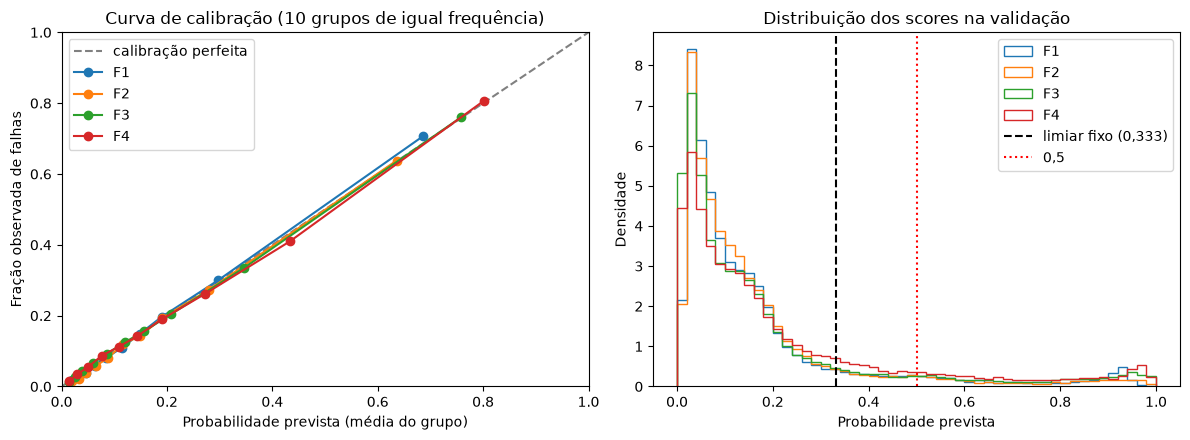

In [25]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))

ax = eixos[0]
ax.plot([0, 1], [0, 1], "--", color="grey", label="calibração perfeita")
for nome, (frac_obs, prob_media) in curvas_cal.items():
    ax.plot(prob_media, frac_obs, "o-", label=nome)
ax.set(xlabel="Probabilidade prevista (média do grupo)", ylabel="Fração observada de falhas",
       title="Curva de calibração (10 grupos de igual frequência)", xlim=(0, 1), ylim=(0, 1))
ax.legend()

ax = eixos[1]
for nome, _, _ in av.FOLDS:
    ax.hist(val_b.loc[val_b["fold"] == nome, "score"], bins=50, range=(0, 1),
            histtype="step", density=True, label=nome)
ax.axvline(LIMIAR_FIXO, color="black", ls="--", label=f"limiar fixo ({LIMIAR_FIXO:.3f})".replace(".", ","))
ax.axvline(0.5, color="red", ls=":", label="0,5")
ax.set(xlabel="Probabilidade prevista", ylabel="Densidade", title="Distribuição dos scores na validação")
ax.legend()

plt.tight_layout()
fig.savefig(PASTA / "task4_calibracao.png", dpi=150)   # para o relatório
plt.show()

**Conclusão.** As probabilidades da Random Forest estão bem calibradas em todos os folds: as curvas seguem a diagonal, o ECE fica entre 0,004 e 0,007, e a probabilidade média prevista fica a menos de 0,005 da prevalência observada, apesar de esta variar entre 15,8 % e 21,1 %. O modelo acompanha, portanto, o nível de risco de cada período, o que é coerente com os históricos do posto refletirem o nível de falhas recente. O Brier skill score, entre 0,27 e 0,33, indica que o modelo reduz o erro de Brier em cerca de 30 % face a prever sempre a prevalência. Perto do limiar fixo complementar (scores entre 0,283 e 0,383), a fração observada de falhas é de 0,318 a 0,339, contra um score médio de 0,327 a 0,329: um score de 0,333 corresponde de facto a cerca de um terço de risco.

**Não se recalibra.** Os alertas do limiar móvel dependem só da ordenação, que uma recalibração monótona não altera, e as probabilidades já estão calibradas.

**Leitura das probabilidades e escolha do limiar.** A distribuição dos scores desloca-se para a direita quando o risco sobe: as sessões perto do limiar fixo são 6,8 % do F4, contra 4,1 % a 4,7 % nos outros folds. É isto que faz um limiar fixo gerar mais alertas nos períodos de mais falhas (secção 9). Como o modelo está calibrado, um limiar fixo mantém constante o significado do alerta (risco de pelo menos um terço), enquanto o limiar móvel mantém constante a carga de trabalho. O critério da secção 8.3 dá prioridade à capacidade de resposta. Os scores de pelo menos 0,5 têm uma fração observada de falhas de cerca de 0,76 (secção 9), coerente com a curva, o que sustenta reservar as ações mais caras para esses alertas.

**Limitações.** Os 10 grupos de igual frequência são largos nos scores altos (o último grupo cobre aproximadamente 0,6 a 1), pelo que a calibração é avaliada com menos detalhe onde há menos sessões. As curvas são da validação; o modelo final é treinado com mais dados, e a sua calibração será confirmada no teste com o Brier e o ECE.

## 11. Modelo final e avaliação no teste

O teste (outubro a dezembro de 2021) é usado **uma única vez**, nesta secção. Todas as decisões foram fixadas antes de o abrir, e os resultados não levam a nenhuma alteração (secção 8.8):

| Decisão | Valor | Onde foi fixada |
|---|---|---|
| Modelo | Random Forest, 200 árvores, folha mínima de 50 sessões, metade das variáveis por divisão; combinação 4, sem informação espacial | Secções 4 e 6 |
| Treino | Todo o desenvolvimento (dezembro de 2019 a setembro de 2021), com o pré-processamento ajustado só nesse período | Secção 8.8 |
| Limiar principal | Limiar móvel de 7 dias com 200 alertas por 1000 sessões; a primeira semana usa as sessões de 24 a 30 de setembro, previstas pelo modelo final | Secções 8.3, 8.8 e 9 |
| Limiar complementar | 0,3328, aplicado sem alterações (`task4_limiar.json`); o 0,5 é reportado para comparação | Secção 9 |
| Referência não operacional | Orçamento exato, comparável com o recall dos folds | Secção 8.4 |
| Baselines | Taxa do posto a 7 dias (limiar móvel e orçamento exato); última sessão do posto anómala (orçamento exato e regra pura, porque é binária) | Secção 8.7 |
| Resultados | Métricas da secção 8.4 no total, por mês e por semana; primeira semana; sessões sem histórico do utilizador; calibração | Secções 8.8, 9.1, 9.4 e 10 |

In [26]:
import time

def carregar_tudo(caminho):
    """Igual a ab.carregar_dev, mas sem remover o teste. Usada só nesta secção."""
    d = pd.read_csv(caminho, parse_dates=["Start Time"])
    d.columns = d.columns.str.strip()
    d["end_cause"] = d["end_cause"].str.strip()
    d["is_Abnormal"] = (~d["end_cause"].isin(ab.NORMAL_CAUSES)).astype(int)
    d = d.sort_values("Start Time", kind="stable").reset_index(drop=True)
    d["hour"] = d["Start Time"].dt.hour
    d["dow"] = d["Start Time"].dt.dayofweek
    for ent, a, b in [("post", "post_hours_since_previous_completed_session", "post_hours_since_previous_completed_abnormal"),
                      ("user", "user_days_since_previous_completed_session", "user_days_since_previous_completed_abnormal")]:
        d[f"{ent}_last_completed_abnormal"] = np.isclose(d[a], d[b]).astype(int)
    return d

INICIO_TESTE, FIM_TESTE = pd.Timestamp("2021-10-01"), pd.Timestamp("2022-01-01")
tudo = carregar_tudo(DATA_PATH)
dev_final = tudo[tudo["Start Time"] < INICIO_TESTE].reset_index(drop=True)
teste = tudo[(tudo["Start Time"] >= INICIO_TESTE) & (tudo["Start Time"] < FIM_TESTE)].reset_index(drop=True)

# o desenvolvimento tem de ser exatamente o df das secções anteriores
assert len(dev_final) == len(df)
assert dev_final["Start Time"].equals(df["Start Time"]) and dev_final["is_Abnormal"].equals(df["is_Abnormal"])
assert len(tudo) == len(dev_final) + len(teste), "há sessões fora do desenvolvimento e do teste"
print(f"desenvolvimento: {len(dev_final):,} sessões | teste: {len(teste):,} sessões "
      f"({teste['Start Time'].min():%Y-%m-%d} a {teste['Start Time'].max():%Y-%m-%d}), prevalência {teste['is_Abnormal'].mean():.1%}")

desenvolvimento: 360,996 sessões | teste: 80,081 sessões (2021-10-01 a 2021-12-31), prevalência 17.6%


In [27]:
with open(PASTA / "task4_limiar.json", encoding="utf-8") as fh:
    limiar_fixado = json.load(fh)
LIMIAR_COMPL = limiar_fixado["limiar_fixo_complementar"]          # lido do ficheiro fixado antes do teste
hp_final = escolhas["hiperparametros_escolhidos"][MODELO_B]
cols_final, modelo_final = ab.criar_pipeline(MODELO_B, GRUPOS_TODOS, ESPACO, **hp_final)
print(modelo_final.named_steps["modelo"])                         # confirmar: 200 árvores, folha 50, max_features 0.5
print(f"limiar complementar: {LIMIAR_COMPL:.4f}")

t0 = time.perf_counter()
modelo_final.fit(dev_final[cols_final], dev_final["is_Abnormal"])
print(f"treino com {len(dev_final):,} sessões: {time.perf_counter() - t0:.0f} s")

RandomForestClassifier(max_features=0.5, min_samples_leaf=50, n_estimators=200,
                       n_jobs=-1, random_state=0)
limiar complementar: 0.3328
treino com 360,996 sessões: 242 s


In [28]:
def metricas_completas(y, score, pred):
    """metricas_limiar (secção 9) mais as métricas de ordenação."""
    r = av.avaliar(y, score, pred=pred)
    return {"sessões": r["n"], "prevalência": r["prevalencia"], **metricas_limiar(y, score, pred),
            "PR-AUC norm.": r["pr_auc_norm"], "ROC-AUC": r["roc_auc"]}

# aquecimento (últimos 7 dias do desenvolvimento) + teste, previstos pelo modelo final
aq_teste = dev_final[dev_final["Start Time"] >= INICIO_TESTE - pd.Timedelta(days=JANELA)]
bloco = pd.concat([aq_teste, teste], ignore_index=True)
bloco["score"] = modelo_final.predict_proba(bloco[cols_final])[:, 1]

sel_t, pred_movel, lims_t = av.alertas_limiar_movel(bloco["Start Time"], bloco["score"].to_numpy(),
                                                    INICIO_TESTE, FIM_TESTE, X_ALERTAS, JANELA)
assert np.array_equal(sel_t, np.arange(len(aq_teste), len(bloco))), "o limiar móvel tem de cobrir o teste, pela ordem"
teste["score"] = bloco["score"].to_numpy()[sel_t]
y_t, s_t = teste["is_Abnormal"].to_numpy(), teste["score"].to_numpy()

# baseline taxa do posto a 7 dias com o mesmo limiar móvel (não precisa de treino)
col7 = "post_previous_abnormal_rate_7D"
_, pred_taxa_movel, lims_taxa = av.alertas_limiar_movel(bloco["Start Time"], bloco[col7].to_numpy(),
                                                        INICIO_TESTE, FIM_TESTE, X_ALERTAS, JANELA)
taxa_t = teste[col7].to_numpy()
ultima_t = teste["post_last_completed_abnormal"].to_numpy().astype(float)

decisoes_t = {   # nome: (score, alertas)
    "RF: limiar móvel de 7 dias (principal)": (s_t, pred_movel),
    f"RF: limiar fixo complementar ({LIMIAR_COMPL:.4f})": (s_t, (s_t >= LIMIAR_COMPL).astype(int)),
    "RF: limiar 0,5": (s_t, (s_t >= 0.5).astype(int)),
    "RF: orçamento exato (referência)": (s_t, av.alertas_por_orcamento(s_t, X_ALERTAS)),
    "Taxa do posto 7 dias: limiar móvel": (taxa_t, pred_taxa_movel),
    "Taxa do posto 7 dias: orçamento exato": (taxa_t, av.alertas_por_orcamento(taxa_t, X_ALERTAS)),
    "Última sessão anómala: orçamento exato": (ultima_t, av.alertas_por_orcamento(ultima_t, X_ALERTAS)),
    "Última sessão anómala: regra pura": (ultima_t, (ultima_t >= 1).astype(int)),
}
tabela_teste = pd.DataFrame({n: metricas_completas(y_t, s, p) for n, (s, p) in decisoes_t.items()}).T

# guardar as previsões do teste (para a interpretação e para reprodutibilidade)
teste[["Start Time", "is_Abnormal", "score"]].assign(alerta=pred_movel) \
    .to_csv(PASTA / "task4_teste_previsoes.csv.gz", index=False)
tabela_teste.round(3)

,sessões,prevalência,alertas /1000,taxa de alertas,precisão,recall,F1,corretos /1000,falsos /1000,falhados /1000,PR-AUC norm.,ROC-AUC
RF: limiar móvel de 7 dias (principal),80081.0,0.176,195.365,0.195,0.468,0.520,0.493,91.520,103.845,84.402,0.437,0.793
RF: limiar fixo complementar (0.3328),80081.0,0.176,140.196,0.140,0.545,0.434,0.484,76.423,63.773,99.499,0.437,0.793
"RF: limiar 0,5",80081.0,0.176,71.390,0.071,0.697,0.283,0.402,49.750,21.641,126.172,0.437,0.793
RF: orçamento exato (referência),80081.0,0.176,199.998,0.200,0.466,0.530,0.496,93.268,106.729,82.654,0.437,0.793
Taxa do posto 7 dias: limiar móvel,80081.0,0.176,192.530,0.193,0.388,0.425,0.406,74.749,117.781,101.173,0.249,0.723
Taxa do posto 7 dias: orçamento exato,80081.0,0.176,199.998,0.200,0.386,0.439,0.411,77.222,122.776,98.700,0.249,0.723
Última sessão anómala: orçamento exato,80081.0,0.176,199.998,0.200,0.389,0.442,0.414,77.821,122.176,98.101,0.129,0.652
Última sessão anómala: regra pura,80081.0,0.176,175.959,0.176,0.426,0.426,0.426,74.937,101.023,100.985,0.129,0.652


In [29]:
rf_orc = tabela_teste.loc["RF: orçamento exato (referência)"]
print("Elegibilidade no teste (secção 8.9):")
print(f"  recall RF {rf_orc['recall']:.3f} > última sessão {tabela_teste.loc['Última sessão anómala: orçamento exato', 'recall']:.3f}:",
      rf_orc["recall"] > tabela_teste.loc["Última sessão anómala: orçamento exato", "recall"])
print(f"  PR-AUC norm. RF {rf_orc['PR-AUC norm.']:.3f} > taxa 7 dias {tabela_teste.loc['Taxa do posto 7 dias: orçamento exato', 'PR-AUC norm.']:.3f}:",
      rf_orc["PR-AUC norm."] > tabela_teste.loc["Taxa do posto 7 dias: orçamento exato", "PR-AUC norm."])

# validação (média dos 4 folds, secção 9) contra teste, para o modelo
comp = pd.DataFrame({
    "validação (média dos folds)": resumo_lim.loc["Limiar móvel de 7 dias"],
    "teste": tabela_teste.loc["RF: limiar móvel de 7 dias (principal)", resumo_lim.columns]})
comp.loc["recall com orçamento exato"] = [resumo_lim.loc["Orçamento exato (referência)", "recall"], rf_orc["recall"]]
comp["diferença"] = comp["teste"] - comp["validação (média dos folds)"]
comp.round(3)

Elegibilidade no teste (secção 8.9):
  recall RF 0.530 > última sessão 0.442: True
  PR-AUC norm. RF 0.437 > taxa 7 dias 0.249: True


,validação (média dos folds),teste,diferença
alertas /1000,203.603,195.365,-8.238
taxa de alertas,0.204,0.195,-0.008
precisão,0.521,0.468,-0.052
recall,0.589,0.520,-0.069
F1,0.552,0.493,-0.059
corretos /1000,106.184,91.520,-14.664
falsos /1000,97.419,103.845,6.426
falhados /1000,73.873,84.402,10.529
recall com orçamento exato,0.588,0.530,-0.058


**Conclusão: resultados globais.** Com o limiar móvel de 7 dias, o modelo final emite 195 alertas por 1000 sessões (orçamento de 200), deteta 52 % das falhas (recall 0,520; precisão 0,468) e deixa 84,4 falhas por 1000 sessões sem aviso. O recall fica 0,010 abaixo do do orçamento exato (0,530), dentro da diferença observada nos folds (−0,014 a +0,008). O modelo é elegível no teste e supera as duas baselines com o mesmo número de alertas: face à taxa do posto a 7 dias com o mesmo limiar móvel, deteta mais 16,8 falhas por 1000 sessões (91,5 contra 74,7) com menos falsos alertas (103,8 contra 117,8). A PR-AUC normalizada é de 0,437, contra 0,249 e 0,129 das baselines.

**Validação contra teste.** O recall com orçamento exato desce de 0,588 (média dos folds) para 0,530 (−0,058), e a PR-AUC normalizada de 0,547 para 0,437. As baselines, que não são treinadas, descem tanto ou mais: a taxa do posto a 7 dias de 0,499 para 0,439 (−0,060) e a última sessão anómala de 0,511 para 0,442 (−0,069) no recall. A descida resulta, portanto, sobretudo do período de teste, em que a persistência das falhas é mais fraca, e não de sobreajuste do modelo. O ganho sobre a referência até aumenta (+0,077 na validação, +0,088 no teste). Parte da diferença pode ainda vir do ligeiro otimismo da validação, porque os mesmos folds serviram para escolher e para comparar (secção 8.9).

**Limiar 0,5 e limiar fixo complementar.** Com 0,5, o modelo emite 71 alertas por 1000 sessões, com precisão de 0,697, mas deteta apenas 28 % das falhas. Face ao 0,5, o limiar escolhido ganha 41,8 alertas corretos por 1000 sessões à custa de 82,2 falsos alertas, cerca de dois por cada falha a mais, como na validação. O limiar fixo complementar (0,3328) gera apenas 140 alertas por 1000 sessões: o teste tem menos falhas (17,6 %) do que o F4 (21,1 %), e como o modelo está calibrado, menos sessões ultrapassam um terço de risco. Na validação, o limiar fixo excedia o orçamento quando o risco subia; no teste, fica 30 % abaixo quando o risco desce, e deteta menos 15 falhas por 1000 sessões do que o limiar móvel. Confirma-se a escolha da secção 9.

In [30]:
mes_t = teste["Start Time"].dt.to_period("M").astype(str).to_numpy()
linhas_mes = {}
for nome in ["RF: limiar móvel de 7 dias (principal)", "Taxa do posto 7 dias: limiar móvel", "Última sessão anómala: orçamento exato"]:
    s, p = decisoes_t[nome]
    for mes in sorted(set(mes_t)):
        m = mes_t == mes
        linhas_mes[(nome, mes)] = metricas_completas(y_t[m], s[m], p[m])
tabela_mes = pd.DataFrame(linhas_mes).T
tabela_mes.index.names = ["decisão", "mês"]
tabela_mes[["sessões", "prevalência", "alertas /1000", "precisão", "recall", "F1",
            "corretos /1000", "falsos /1000", "falhados /1000", "PR-AUC norm."]].round(3)

sessões  prevalência  alertas /1000  precisão  recall     F1  corretos /1000  falsos /1000  falhados /1000  PR-AUC norm.
decisão                                mês                                                                                                                              
RF: limiar móvel de 7 dias (principal) 2021-10  27794.0        0.186        173.059     0.517   0.481  0.499          89.552        83.507          96.460         0.456
                                       2021-11  25669.0        0.165        202.735     0.424   0.521  0.467          85.940       116.795          79.084         0.384
                                       2021-12  26618.0        0.176        211.549     0.468   0.563  0.511          98.956       112.593          76.940         0.461
Taxa do posto 7 dias: limiar móvel     2021-10  27794.0        0.186        169.281     0.423   0.385  0.403          71.670        97.611         114.341         0.265
                                       2021-11  25669.0        0.165        206.007     0.346   0.432  0.384          71.214       134.793          93.810         0.200
                                       2021-12  26618.0        0.176        203.809     0.399   0.463  0.429          81.374       122.436          94.523         0.267
Última sessão anómala: orçamento exato 2021-10  27794.0        0.186        210.297     0.396   0.448  0.420          83.255       127.042         102.756         0.131
                                       2021-11  25669.0        0.165        189.139     0.362   0.415  0.387          68.526       120.612          96.498         0.110
                                       2021-12  26618.0        0.176        199.714     0.406   0.461  0.432          81.111       118.604          94.785         0.146

**Conclusão: por mês.** O modelo supera as duas baselines nos três meses, no recall e na PR-AUC normalizada (0,456; 0,384; 0,461, contra 0,200 a 0,267 da taxa a 7 dias). O recall sobe de outubro para dezembro (0,481; 0,521; 0,563). Em outubro, o limiar móvel emite apenas 173 alertas por 1000 sessões, porque nas primeiras semanas ainda reflete o risco mais alto de setembro (ver por semana). Novembro tem a precisão mais baixa (0,424), por ter a prevalência mais baixa (16,5 %). Não há sinal de deterioração ao longo dos três meses.

In [31]:
inicios_sem = pd.to_datetime(lims_t["semana"]).to_numpy()
semana_idx = np.searchsorted(inicios_sem, teste["Start Time"].to_numpy(), side="right") - 1
linhas_sem_t = {}
for k, ini in enumerate(inicios_sem):
    m = semana_idx == k
    r = metricas_limiar(y_t[m], s_t[m], pred_movel[m])
    linhas_sem_t[pd.Timestamp(ini).date()] = {"sessões": int(m.sum()), "prevalência": y_t[m].mean(),
                                              "limiar": lims_t.loc[k, "limiar"], "alertas /1000": r["alertas /1000"],
                                              "precisão": r["precisão"], "recall": r["recall"],
                                              "taxa 7 dias: alertas /1000": 1000 * pred_taxa_movel[m].mean()}
tabela_sem_t = pd.DataFrame(linhas_sem_t).T
w, n = tabela_sem_t["alertas /1000"], tabela_sem_t["sessões"]
ini0 = pd.Timestamp(inicios_sem[0])
fim0 = pd.Timestamp(inicios_sem[1]) - pd.Timedelta(days=1)
w, n = w.astype(float), n.astype(float)
print(f"1.ª semana ({ini0:%d/%m} a {fim0:%d/%m}): {w.iloc[0]:.0f} alertas por 1000 | "
      f"restantes semanas: {np.average(w.iloc[1:], weights=n.iloc[1:]):.0f} | "
      f"semana mín. {w.min():.0f}, máx. {w.max():.0f}")
tabela_sem_t.round(3)

1.ª semana (01/10 a 03/10): 217 alertas por 1000 | restantes semanas: 194 | semana mín. 142, máx. 283


,sessões,prevalência,limiar,alertas /1000,precisão,recall,taxa 7 dias: alertas /1000
2021-10-01,3209.0,0.237,0.368,216.890,0.592,0.541,226.550
2021-10-04,6083.0,0.200,0.396,142.035,0.635,0.451,136.939
2021-10-11,6318.0,0.172,0.316,152.896,0.500,0.444,146.724
2021-10-18,6268.0,0.176,0.261,190.651,0.464,0.502,212.668
2021-10-25,5916.0,0.168,0.253,184.077,0.450,0.492,149.594
2021-11-01,5435.0,0.154,0.240,189.144,0.402,0.495,211.776
2021-11-08,6212.0,0.164,0.233,206.214,0.418,0.527,190.599
2021-11-15,6043.0,0.160,0.238,192.620,0.418,0.503,239.120
2021-11-22,6309.0,0.181,0.234,223.649,0.446,0.550,176.573
2021-11-29,6359.0,0.173,0.251,201.132,0.466,0.542,222.047


**Conclusão: por semana.** A carga semanal varia entre 142 e 283 alertas por 1000 sessões, como na validação (108 a 293). O limiar acompanha o risco com atraso: nas semanas de 4 e 11 de outubro, calculado com semanas de prevalência mais alta (23,7 % na primeira semana e o fim de setembro), fica em 0,396 e 0,316 e gera apenas 142 e 153 alertas; a partir da terceira semana estabiliza entre 0,23 e 0,26. A última semana (27 a 31 de dezembro) tem a carga mais alta (283), com prevalência de 21,7 %.

**Primeira semana.** De 1 a 3 de outubro, com o limiar calculado com scores de sessões de treino (24 a 30 de setembro), houve 217 alertas por 1000 sessões, contra 194 nas restantes semanas (+12 %). É o mesmo sentido observado em três dos quatro folds, e o efeito no trimestre é pequeno (3 dias em 92). Como essa semana também teve prevalência alta (23,7 %), não é possível separar o efeito dos scores de treino da subida real do risco.

In [32]:
# Sessões sem histórico do utilizador (alertas decididos pelo limiar global, como na Tabela 41)
sem_hist = teste["user_no_previous_completed_session"].to_numpy() == 1
linhas_grupo = {}
for nome in ["RF: limiar móvel de 7 dias (principal)", "Taxa do posto 7 dias: limiar móvel", "Última sessão anómala: orçamento exato"]:
    s, p = decisoes_t[nome]
    for grupo, m in [("sem histórico do utilizador", sem_hist), ("com histórico do utilizador", ~sem_hist)]:
        linhas_grupo[(nome, grupo)] = {"% das sessões": m.mean(), "prevalência": y_t[m].mean(),
                                       "% dos alertas": p[m].sum() / p.sum(), "recall": metricas_limiar(y_t[m], s[m], p[m])["recall"]}
display(pd.DataFrame(linhas_grupo).T.round(3))

# Calibração no teste (secção 10)
frac_obs_t, prob_med_t = calibration_curve(y_t, s_t, n_bins=10, strategy="quantile")
brier_t, prev_t = brier_score_loss(y_t, s_t), y_t.mean()
print(f"prevalência {prev_t:.4f} | probabilidade média prevista {s_t.mean():.4f} | Brier {brier_t:.4f} "
      f"| Brier skill score {1 - brier_t / (prev_t * (1 - prev_t)):.3f} "
      f"| ECE {ot.metricas_probabilisticas({'teste': (y_t, s_t, None)})['ECE']:.4f}")
pd.DataFrame({"probabilidade média prevista": prob_med_t, "fração observada de falhas": frac_obs_t}).round(3)

% das sessões  prevalência  % dos alertas  recall
RF: limiar móvel de 7 dias (principal) sem histórico do utilizador           0.13        0.176          0.119   0.367
                                       com histórico do utilizador           0.87        0.176          0.881   0.543
Taxa do posto 7 dias: limiar móvel     sem histórico do utilizador           0.13        0.176          0.162   0.437
                                       com histórico do utilizador           0.87        0.176          0.838   0.423
Última sessão anómala: orçamento exato sem histórico do utilizador           0.13        0.176          0.114   0.303
                                       com histórico do utilizador           0.87        0.176          0.886   0.463

prevalência 0.1759 | probabilidade média prevista 0.1798 | Brier 0.1127 | Brier skill score 0.223 | ECE 0.0063


,probabilidade média prevista,fração observada de falhas
0,0.019,0.023
1,0.040,0.034
2,0.062,0.066
3,0.087,0.090
4,0.112,0.110
5,0.138,0.124
6,0.171,0.160
7,0.221,0.219
8,0.323,0.313
9,0.626,0.620


**Conclusão: sessões sem histórico do utilizador.** Representam 13 % das sessões do teste, com a mesma prevalência das restantes (17,6 %), mas recebem só 11,9 % dos alertas, e o recall é de 0,367, contra 0,543 nas sessões com histórico. Neste grupo, a taxa do posto a 7 dias com o mesmo limiar móvel deteta mais falhas (0,437) do que o modelo: sem histórico do utilizador, o modelo subestima o risco destas sessões face ao que a informação do posto, sozinha, indica. Isto confirma a ressalva das secções 9.1 e 9.4: o ganho global vem dos utilizadores com histórico, e os utilizadores novos ficam pior cobertos. Uma alternativa a avaliar em operação seria usar, nestas sessões, um modelo só com o histórico do posto.

**Calibração no teste.** A probabilidade média prevista (0,180) fica a 0,004 da prevalência (0,176), o ECE é de 0,0063 e a curva segue a diagonal, com uma ligeira sobrestimação nos grupos intermédios (por exemplo, 0,138 previsto contra 0,124 observado). O Brier skill score (0,223) é mais baixo do que na validação (0,27 a 0,33), em linha com a ordenação mais fraca no teste. As probabilidades continuam a poder ser lidas como risco.

## 12. Interpretação do modelo final

**Pergunta.** Que informação usa o modelo final para decidir? A interpretação é feita ao nível dos grupos de variáveis da ablação (secção 9.1), o que permite comparar os dois resultados.

**Método principal: importância por permutação de grupos, no teste.** Para cada grupo, baralham-se em conjunto todas as suas colunas no teste (a mesma permutação de linhas para todas), mantendo as restantes, e mede-se quanto descem o recall com 200 alertas (orçamento exato) e a PR-AUC normalizada. Cinco repetições dão a média e o desvio. Baralhar o grupo inteiro evita o principal problema da permutação de variáveis isoladas: com variáveis muito correlacionadas, como os atributos históricos (secção 5.6), o modelo recupera a informação a partir das vizinhas e a importância de cada uma fica subestimada. Usa-se o teste porque é o único conjunto que o modelo final não viu no treino; nenhuma decisão é alterada.

| Grupo | Variáveis |
|---|---|
| Tempo | hora e dia da semana |
| Meteorologia | temperatura, humidade e precipitação |
| Tarifa | preço da eletricidade |
| Tempo + tarifa | as duas anteriores juntas, porque a tarifa é função da hora |
| Histórico do posto | 12 variáveis |
| Histórico do utilizador | 12 variáveis |
| Os dois históricos | 24 variáveis |

**Complementos.** (1) Permutação variável a variável, para ver quais pesam mais dentro dos grupos, com a ressalva da correlação. (2) Importância por impureza (MDI) da Random Forest, somada por grupo, para comparar com a secção 9.2. É calculada com os dados de treino e favorece variáveis contínuas com muitos valores.

**Porque não SHAP.** Com 200 árvores e 80 mil sessões, o custo é elevado; os valores SHAP são também afetados pelas variáveis correlacionadas, e medem contribuições para o score, não para a métrica de decisão. A permutação responde diretamente à pergunta operacional: quanto perde a deteção sem esta informação.

In [33]:
NOMES_GRUPOS = {"tempo": "Tempo", "meteorologia": "Meteorologia", "tarifa": "Tarifa",
                "historico_posto": "Histórico do posto", "historico_utilizador": "Histórico do utilizador"}
rf_final = modelo_final.named_steps["modelo"]
pre_final = modelo_final.named_steps["pre"]
# sem one-hot (sem posto e com a hora numérica), cada coluna de saída corresponde a uma coluna de entrada
nomes_saida = [c for nome, _, cs in pre_final.transformers_ if nome != "remainder" for c in cs]
assert len(nomes_saida) == rf_final.n_features_in_, "o número de colunas não bate com o modelo"
grupo_de = {c: g for g, cs in ab.GRUPOS.items() for c in cs}

mdi = pd.Series(rf_final.feature_importances_, index=nomes_saida)
mdi_grupo = mdi.groupby(mdi.index.map(grupo_de)).sum().rename(index=NOMES_GRUPOS).sort_values(ascending=False)
print("Importância por impureza (MDI), soma por grupo (treino; total = 1):")
display(mdi_grupo.round(3).to_frame("MDI"))
print("As 10 variáveis com maior MDI:")
mdi.sort_values(ascending=False).head(10).round(3).to_frame("MDI")

Importância por impureza (MDI), soma por grupo (treino; total = 1):


,MDI
Histórico do posto,0.790
Histórico do utilizador,0.172
Meteorologia,0.025
Tempo,0.011
Tarifa,0.001


As 10 variáveis com maior MDI:


,MDI
post_previous_abnormal_rate_1D,0.275
post_last_completed_abnormal,0.161
post_previous_abnormal_rate_7D,0.127
post_hours_since_previous_completed_abnormal,0.063
post_previous_abnormal_rate_30D,0.061
user_last_completed_abnormal,0.044
post_previous_abnormal_1D,0.037
user_previous_abnormal_rate_30D,0.036
user_previous_abnormal_rate_180D,0.034
user_days_since_previous_completed_abnormal,0.027


Sem permutação: recall 0.5302 | PR-AUC norm. 0.4373
Tempo                         6 s
Meteorologia                 11 s
Tarifa                       16 s
Tempo + tarifa               21 s
Histórico do posto           26 s
Histórico do utilizador      30 s
Os dois históricos           36 s


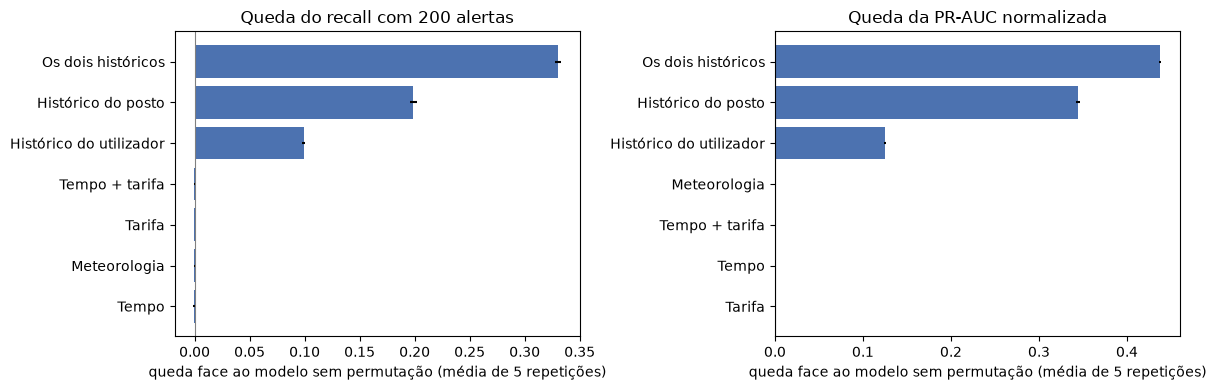

,variáveis,queda do recall (média),queda do recall (desvio),queda da PR-AUC norm. (média),queda da PR-AUC norm. (desvio)
Tempo,2.0,-0.0006,0.0007,0.0001,0.0001
Meteorologia,3.0,-0.0003,0.0005,0.0004,0.0002
Tarifa,1.0,-0.0003,0.0001,0.0001,0.0000
Tempo + tarifa,3.0,-0.0003,0.0005,0.0002,0.0001
Histórico do posto,12.0,0.1987,0.0031,0.3445,0.0020
Histórico do utilizador,12.0,0.0990,0.0013,0.1251,0.0012
Os dois históricos,24.0,0.3303,0.0030,0.4376,0.0007


In [34]:
N_REP = 5
X_teste = teste[cols_final]

def metricas_perm(score):
    r = av.avaliar(y_t, score, pred=av.alertas_por_orcamento(score, X_ALERTAS))
    return r["recall"], r["pr_auc_norm"]

s_base = modelo_final.predict_proba(X_teste)[:, 1]
assert np.allclose(s_base, s_t), "os scores têm de ser os da secção 11"
recall_base, prauc_base = metricas_perm(s_base)
print(f"Sem permutação: recall {recall_base:.4f} | PR-AUC norm. {prauc_base:.4f}")

GRUPOS_PERM = {
    "Tempo": ab.GRUPOS["tempo"],
    "Meteorologia": ab.GRUPOS["meteorologia"],
    "Tarifa": ab.GRUPOS["tarifa"],
    "Tempo + tarifa": ab.GRUPOS["tempo"] + ab.GRUPOS["tarifa"],
    "Histórico do posto": ab.GRUPOS["historico_posto"],
    "Histórico do utilizador": ab.GRUPOS["historico_utilizador"],
    "Os dois históricos": ab.GRUPOS["historico_posto"] + ab.GRUPOS["historico_utilizador"],
}

rng_perm = np.random.default_rng(0)
t0 = time.perf_counter()
linhas_perm = {}
for grupo, cols in GRUPOS_PERM.items():
    quedas_r, quedas_p = [], []
    for _ in range(N_REP):
        Xp = X_teste.copy()
        Xp[cols] = Xp[cols].to_numpy()[rng_perm.permutation(len(Xp))]   # mesmas linhas para todo o grupo
        r, p = metricas_perm(modelo_final.predict_proba(Xp)[:, 1])
        quedas_r.append(recall_base - r); quedas_p.append(prauc_base - p)
    linhas_perm[grupo] = {"variáveis": len(cols),
                          "queda do recall (média)": np.mean(quedas_r), "queda do recall (desvio)": np.std(quedas_r, ddof=1),
                          "queda da PR-AUC norm. (média)": np.mean(quedas_p), "queda da PR-AUC norm. (desvio)": np.std(quedas_p, ddof=1)}
    print(f"{grupo:<25} {time.perf_counter() - t0:5.0f} s")
tabela_perm = pd.DataFrame(linhas_perm).T

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, titulo in [(eixos[0], "queda do recall", "Queda do recall com 200 alertas"),
                        (eixos[1], "queda da PR-AUC norm.", "Queda da PR-AUC normalizada")]:
    t = tabela_perm.sort_values(f"{col} (média)")
    ax.barh(t.index, t[f"{col} (média)"], xerr=t[f"{col} (desvio)"], color="#4C72B0")
    ax.axvline(0, color="grey", lw=0.8)
    ax.set(title=titulo, xlabel="queda face ao modelo sem permutação (média de 5 repetições)")
plt.tight_layout()
fig.savefig(PASTA / "task4_importancia_grupos.png", dpi=150)
plt.show()
tabela_perm.round(4)

In [35]:
N_REP_VAR = 3
t0 = time.perf_counter()
linhas_var = {}
for c in cols_final:
    quedas_r, quedas_p = [], []
    for _ in range(N_REP_VAR):
        Xp = X_teste.copy()
        Xp[c] = Xp[c].to_numpy()[rng_perm.permutation(len(Xp))]
        r, p = metricas_perm(modelo_final.predict_proba(Xp)[:, 1])
        quedas_r.append(recall_base - r); quedas_p.append(prauc_base - p)
    linhas_var[c] = {"grupo": NOMES_GRUPOS[grupo_de[c]],
                     "queda do recall": np.mean(quedas_r), "queda da PR-AUC norm.": np.mean(quedas_p),
                     "MDI": mdi[c]}
print(f"{len(cols_final)} variáveis em {time.perf_counter() - t0:.0f} s")
tabela_var = pd.DataFrame(linhas_var).T.sort_values("queda da PR-AUC norm.", ascending=False)
tabela_var.head(15).round(4)

30 variáveis em 91 s


,grupo,queda do recall,queda da PR-AUC norm.,MDI
post_previous_abnormal_rate_1D,Histórico do posto,0.017604,0.078113,0.274884
post_last_completed_abnormal,Histórico do posto,0.003076,0.043855,0.161454
user_previous_abnormal_rate_30D,Histórico do utilizador,0.009559,0.017084,0.036023
user_previous_abnormal_rate_180D,Histórico do utilizador,0.005324,0.013672,0.033707
post_previous_abnormal_rate_7D,Histórico do posto,0.013818,0.013216,0.127237
post_previous_abnormal_rate_30D,Histórico do posto,0.006057,0.012804,0.060832
post_hours_since_previous_completed_abnormal,Histórico do posto,0.003407,0.01084,0.06282
user_last_completed_abnormal,Histórico do utilizador,0.006814,0.00905,0.044013
user_days_since_previous_completed_abnormal,Histórico do utilizador,0.001372,0.004685,0.02718
user_previous_abnormal_180D,Histórico do utilizador,0.001467,0.001716,0.004972


**Conclusão.** O modelo final decide quase só com os atributos históricos. Baralhando os dois históricos em conjunto, o recall com 200 alertas cai 0,330 (de 0,530 para cerca de 0,20, o valor de alertar ao acaso) e a PR-AUC normalizada cai 0,438, praticamente para zero: sem histórico, a hora, a meteorologia e a tarifa não têm poder de previsão. O histórico do posto é o grupo mais importante (−0,199 de recall e −0,345 de PR-AUC normalizada), seguido do histórico do utilizador (−0,099 e −0,125). O tempo, a meteorologia e a tarifa, isolados ou com a hora e a tarifa juntas, têm quedas de no máximo 0,0006, da ordem da variação entre repetições. A importância por impureza dá a mesma ordenação (posto 0,79; utilizador 0,17; meteorologia 0,025; tempo 0,011; tarifa 0,001).

Dentro dos grupos, as variáveis mais importantes são a taxa de anomalias do posto no último dia, a última sessão do posto anómala, as taxas de anomalias do utilizador a 30 e 180 dias, a taxa do posto a 7 dias e a última sessão do utilizador anómala. O modelo deteta sobretudo **episódios de falha recentes no posto** e, em segundo lugar, **utilizadores ou veículos com falhas repetidas**. É o mesmo padrão dos coeficientes da logística e das divisões da árvore (secção 9.2) e da persistência das falhas observada na Task 1 (secção 5.2). Explica também dois resultados do teste: o desempenho desce quando a persistência das falhas é mais fraca, e as sessões sem histórico do utilizador ficam pior cobertas (secção 11).

**Limitações do método.**
1. **Variáveis correlacionadas.** Baralhada sozinha, cada variável histórica parece pouco importante, porque o modelo recupera a informação nas vizinhas: as quedas individuais somam cerca de metade da queda dos dois grupos. A permutação por grupo resolve isto dentro dos grupos, mas não entre eles: o posto e o utilizador separados somam 0,298, contra 0,330 juntos. A importância das variáveis individuais deve ser lida como ordenação aproximada, e não como contributo exato.
2. **Combinações irrealistas.** Baralhar cria sessões que não existem (por exemplo, uma taxa de anomalias alta no último dia num posto sem sessões nesse dia), pelo que o modelo é avaliado fora da distribuição dos dados, o que pode exagerar a importância.
3. **Dependência do modelo, não valor da informação.** A permutação mede quanto este modelo depende de cada grupo, não quanto se perderia se o modelo fosse treinado sem ele. O histórico do utilizador custa 0,099 de recall aqui, mas na ablação (secção 9.1) acrescentava apenas +0,018 a +0,030, porque sem ele o histórico do posto compensa a maior parte.
4. **Associação, não causalidade.** Uma taxa de anomalias alta não causa a falha seguinte; indica um posto em avaria ou um veículo com problemas.
5. **Global e sem sentido do efeito.** A permutação diz quanto cada grupo pesa no conjunto das sessões, mas não explica uma sessão concreta nem o sentido do efeito, que se lê na logística (secção 9.2): taxas e indicadores de falha mais altos aumentam o risco.
6. **Período.** É calculada no teste (outubro a dezembro de 2021); com outro nível de persistência das falhas, os pesos podem mudar.
7. **MDI.** É calculada com os dados de treino e favorece variáveis contínuas com muitos valores: atribui 2,5 % à meteorologia, que pela permutação não tem importância. Serve apenas como confirmação.

## 13. Conclusões do limiar, do teste e da interpretação

**Limiar de decisão.** O critério é uma restrição da taxa de alertas: o máximo de falhas detetadas com 200 alertas por 1000 sessões (secção 8.3). É aplicado com um limiar móvel de 7 dias, recalculado à segunda-feira só com scores passados (secção 8.8). Na validação, cumpre o orçamento em todos os folds (191 a 209 alertas por 1000 sessões) e deteta 59 % das falhas, contra 38 % com o limiar 0,5, à custa de cerca de dois falsos alertas por cada falha a mais detetada. Um limiar de probabilidade fixo não respeita a capacidade quando o nível de risco muda.

**Calibração.** As probabilidades da Random Forest estão bem calibradas na validação e no teste (ECE de 0,004 a 0,007). Não foi necessária recalibração, e os alertas do limiar móvel não dependem dela.

**Teste.** O modelo final emite 195 alertas por 1000 sessões e deteta 52 % das falhas (recall 0,520; precisão 0,468). Supera as duas baselines em todos os meses e deteta mais 16,8 falhas por 1000 sessões do que a taxa do posto a 7 dias com o mesmo limiar. O desempenho fica abaixo do da validação (recall com orçamento exato de 0,530, contra 0,588), mas as baselines descem tanto ou mais, pelo que a descida vem sobretudo do período de teste. O limiar fixo complementar (0,333) gerou apenas 140 alertas por 1000 sessões, o que confirma a escolha do limiar móvel. As sessões sem histórico do utilizador são o ponto fraco (recall de 0,367, abaixo da taxa do posto a 7 dias neste grupo).

**Interpretação.** O modelo assenta quase só nos atributos históricos, sobretudo nos episódios de falha recentes do posto e, em segundo lugar, no histórico de falhas do utilizador. A hora, a meteorologia e a tarifa não contribuem. Responde-se assim à pergunta do projeto: a informação disponível no início da sessão permite prever as sessões anómalas bem acima das regras simples, mas quase toda a capacidade de previsão vem do histórico recente de falhas, e não do contexto da sessão.

In [36]:
print(f"tempo total deste caderno: {time.perf_counter() - T_INICIO:.0f} s")

tempo total deste caderno: 1467 s
